# Tri-Modal Catalogue Retrieval + Nano Banana Material Rendering

**Kaggle settings:** Accelerator **GPU T4 x2** · Internet **On** · Persistence **Files only** (optional, keeps `/kaggle/working` between sessions)

| Input | Contents |
|---|---|
| `/kaggle/input/datasets/mayankr293/terucon-catalogue-1/Superbond colour image.pdf` | The catalogue PDF (set `PDF_PATH` at the top of Cell 1; a folder of PDFs also works) |
| Kaggle secret **`VERTEX_AI_SA_JSON_1`** | Full GCP service-account JSON (role **Vertex AI User**). Add-ons → Secrets → add it and tick the box to attach it to this notebook. |
| `/kaggle/input/query-photos/` *(optional)* | Real phone photos to search with |
| `/kaggle/input/target-scenes/` *(optional)* | Scene photos to re-surface with the matched material |

| Output (`/kaggle/working/`) | Purpose |
|---|---|
| `state.sqlite` | Source of truth: pages, items, captions, vectors, errors (resumable) |
| `manifest.parquet` | Backtracking lineage: product_id → PDF, page, bboxes, crop, sha256, status |
| `page_audit.parquet` | Per-page extraction audit (method, candidates, errors) |
| `crops/`, `index/`, `renders/`, `backtrace/` | Crops, FAISS indexes, Nano Banana renders, provenance overlays |

Every stage is idempotent: re-running the notebook skips finished pages, captions and vectors.

In [1]:
# =============================================================================
# CELL 1 — Vibe check, dependencies, imports, logging, utilities, dual-T4 verification
# =============================================================================
import os
import sys
import subprocess
import importlib
import importlib.metadata
import importlib.util
import base64
import json
import shutil
import socket
from pathlib import Path

# ----------------------------------------------------------------- user settings
PDF_PATH = Path("/kaggle/input/datasets/mayankr293/terucon-catalogue-1/Superbond colour image.pdf")
SA_SECRET_NAME = "VERTEX_AI_SA_JSON_1"  # Kaggle secret holding the full service-account JSON
KAGGLE_INPUT_ROOT = Path("/kaggle/input")
KAGGLE_WORK_DIR = Path("/kaggle/working")
REQUIRE_DUAL_GPU = os.environ.get("CATALOG_REQUIRE_DUAL_GPU", "1") == "1"
VERTEX_PROBE_MODELS = ("gemini-2.5-flash", "gemini-3.5-flash")


# ----------------------------------------------------------------- Kaggle secret -> service account
class SecretUnavailableError(RuntimeError):
    pass


_SECRET_CACHE = {}


def parse_service_account_json(raw_text, secret_name):
    """Accept the JSON as pasted (also tolerates surrounding quotes, double-encoding or base64)."""
    text = (raw_text or "").strip()
    if not text:
        raise SecretUnavailableError(f"Kaggle secret '{secret_name}' is empty.")
    if len(text) >= 2 and text[0] == text[-1] and text[0] in ("'", '"') and not text.startswith('"{'):
        text = text[1:-1].strip()
    info = None
    try:
        info = json.loads(text)
        if isinstance(info, str):
            info = json.loads(info)  # JSON pasted as a JSON string
    except json.JSONDecodeError:
        try:
            info = json.loads(base64.b64decode(text, validate=True).decode("utf-8"))
        except Exception as exc:
            raise SecretUnavailableError(
                f"Kaggle secret '{secret_name}' is not valid service-account JSON. Paste the whole downloaded "
                "key file contents, starting with '{' and ending with '}'.") from exc
    if not isinstance(info, dict) or info.get("type") != "service_account":
        raise SecretUnavailableError(f"Kaggle secret '{secret_name}' is JSON but not a service-account key "
                                     "(expected \"type\": \"service_account\").")
    missing = [key for key in ("project_id", "private_key", "client_email", "token_uri") if not info.get(key)]
    if missing:
        raise SecretUnavailableError(f"Kaggle secret '{secret_name}' is missing fields: {missing}")
    if "\\n" in info["private_key"]:
        info["private_key"] = info["private_key"].replace("\\n", "\n")  # key pasted with escaped newlines
    if "BEGIN PRIVATE KEY" not in info["private_key"]:
        raise SecretUnavailableError(f"Kaggle secret '{secret_name}': private_key is not a PEM key.")
    return info


def load_service_account_info(secret_name=SA_SECRET_NAME):
    """Read the service-account JSON from Kaggle Secrets (cached; the key is never printed or written)."""
    if secret_name in _SECRET_CACHE:
        return dict(_SECRET_CACHE[secret_name])
    try:
        from kaggle_secrets import UserSecretsClient
    except ImportError as exc:
        raise SecretUnavailableError("kaggle_secrets is only available inside a Kaggle notebook.") from exc
    try:
        user_secrets = UserSecretsClient()
        raw_secret = user_secrets.get_secret(secret_name)
    except Exception as exc:
        raise SecretUnavailableError(
            f"Could not read Kaggle secret '{secret_name}' ({type(exc).__name__}). Add it under Add-ons -> "
            "Secrets and tick the checkbox so it is attached to this notebook.") from exc
    info = parse_service_account_json(raw_secret, secret_name)
    _SECRET_CACHE[secret_name] = info
    return dict(info)


def locate_pdf_source(pdf_path, search_root=None):
    """Return pdf_path if it exists, else a file with the same name anywhere under /kaggle/input
    (Kaggle mounts datasets at /kaggle/input/<slug>/ or /kaggle/input/datasets/<user>/<slug>/)."""
    pdf_path = Path(pdf_path)
    if pdf_path.exists():
        return pdf_path
    search_root = Path(search_root) if search_root is not None else KAGGLE_INPUT_ROOT
    if pdf_path.suffix.lower() == ".pdf" and search_root.exists():
        matches = sorted(search_root.rglob(pdf_path.name))
        if matches:
            return matches[0]
    return None


# ----------------------------------------------------------------- vibe check
VIBE_ICONS = {"PASS": "✅ PASS", "WARN": "⚠️ WARN", "FAIL": "❌ FAIL"}


class VibeCheckFailed(RuntimeError):
    pass


def _vibe(check, status, detail):
    return {"check": check, "status": status, "detail": detail}


def vibe_environment():
    on_kaggle = Path("/kaggle").is_dir() or "KAGGLE_KERNEL_RUN_TYPE" in os.environ
    detail = f"Python {sys.version.split()[0]} | Kaggle={'yes' if on_kaggle else 'no'}"
    return _vibe("environment", "PASS" if on_kaggle else "WARN", detail)


def vibe_gpus(require_dual_gpu):
    """nvidia-smi instead of torch, so nothing heavy is imported before the check passes."""
    try:
        output = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                                capture_output=True, text=True, timeout=30).stdout.strip()
        gpus = [line.strip() for line in output.splitlines() if line.strip()]
    except (FileNotFoundError, subprocess.TimeoutExpired):
        gpus = []
    status = "PASS"
    detail = f"{len(gpus)} GPU(s): " + ("; ".join(gpus) if gpus else "none")
    if len(gpus) != 2:
        status = "FAIL" if require_dual_gpu else "WARN"
        detail += " -> set Settings > Accelerator to 'GPU T4 x2'"
    elif not all("T4" in gpu for gpu in gpus):
        status = "WARN"
        detail += " (not T4; batch sizes were tuned for 16 GB T4s)"
    return _vibe("gpus", status, detail)


def vibe_internet():
    hosts = {"huggingface.co": True, "aiplatform.googleapis.com": True, "oauth2.googleapis.com": True,
             "pypi.org": False}
    unreachable_required = []
    unreachable_optional = []
    for host, required in hosts.items():
        try:
            with socket.create_connection((host, 443), timeout=6):
                pass
        except OSError:
            if required:
                unreachable_required.append(host)
            else:
                unreachable_optional.append(host)
    if unreachable_required:
        return _vibe("internet", "FAIL", f"cannot reach {unreachable_required} -> turn on Settings > Internet")
    if unreachable_optional:
        return _vibe("internet", "WARN", f"cannot reach {unreachable_optional}")
    return _vibe("internet", "PASS", "huggingface.co, Vertex AI, OAuth and PyPI reachable")


def vibe_secret(secret_name):
    try:
        info = load_service_account_info(secret_name)
    except SecretUnavailableError as exc:
        return _vibe("secret", "FAIL", str(exc))
    return _vibe("secret", "PASS", f"'{secret_name}' -> project={info['project_id']} | {info['client_email']}")


def vibe_pdf(pdf_path):
    found = locate_pdf_source(pdf_path)
    if found is None:
        listing = sorted(str(path) for path in KAGGLE_INPUT_ROOT.glob("*")) if KAGGLE_INPUT_ROOT.exists() else []
        return _vibe("pdf", "FAIL", f"not found: {pdf_path} | /kaggle/input contains {listing[:10]}")
    pdf_files = [found] if found.is_file() else sorted(path for path in found.rglob("*.pdf") if path.is_file())
    if not pdf_files:
        return _vibe("pdf", "FAIL", f"no .pdf files under {found}")
    problems = []
    total_bytes = 0
    for pdf_file in pdf_files:
        size = pdf_file.stat().st_size
        total_bytes += size
        with open(pdf_file, "rb") as handle:
            head = handle.read(1024)
            handle.seek(max(0, size - 65536))
            tail = handle.read()
        if b"%PDF-" not in head:
            problems.append(f"{pdf_file.name}: no %PDF header")
        elif b"%%EOF" not in tail:
            problems.append(f"{pdf_file.name}: no %%EOF marker (upload may be truncated)")
        if b"/Encrypt" in tail:
            problems.append(f"{pdf_file.name}: encrypted")
    detail = f"{len(pdf_files)} PDF(s), {total_bytes / 1024 ** 2:.1f} MB at {found}"
    if found != Path(pdf_path):
        detail += " (configured path missing; found by file name)"
    if any("no %PDF header" in problem for problem in problems):
        return _vibe("pdf", "FAIL", detail + " | " + "; ".join(problems))
    if problems or found != Path(pdf_path):
        return _vibe("pdf", "WARN", detail + (" | " + "; ".join(problems) if problems else ""))
    return _vibe("pdf", "PASS", detail)


def vibe_resources(work_dir=KAGGLE_WORK_DIR):
    target = work_dir if work_dir.exists() else Path.cwd()
    free_gb = shutil.disk_usage(target).free / 1024 ** 3
    available_gb = None
    try:
        with open("/proc/meminfo") as handle:
            for line in handle:
                if line.startswith("MemAvailable:"):
                    available_gb = int(line.split()[1]) / 1024 ** 2
    except OSError:
        pass
    detail = f"disk free {free_gb:.1f} GB in {target}" + (f" | RAM available {available_gb:.1f} GB" if available_gb else "")
    low = free_gb < 5 or (available_gb is not None and available_gb < 8)
    return _vibe("resources", "WARN" if low else "PASS", detail)


def print_vibe_report(title, results):
    print(f"\n{'=' * 22} {title} {'=' * 22}")
    width = max(len(result["check"]) for result in results)
    for result in results:
        print(f"{VIBE_ICONS[result['status']]:<10} {result['check']:<{width}}  {result['detail']}")
    print("=" * (46 + len(title)))


def raise_on_vibe_failures(results, stage):
    failures = [result for result in results if result["status"] == "FAIL"]
    if failures:
        summary = "; ".join(f"{result['check']}: {result['detail']}" for result in failures)
        raise VibeCheckFailed(f"Vibe check failed ({stage}). Fix and re-run Cell 1. {summary}")


def run_vibe_check_preflight(pdf_path=PDF_PATH, secret_name=SA_SECRET_NAME, require_dual_gpu=REQUIRE_DUAL_GPU):
    """Stage 1: standard library only, runs before anything is installed or loaded."""
    results = [vibe_environment(), vibe_gpus(require_dual_gpu), vibe_internet(), vibe_secret(secret_name),
               vibe_pdf(pdf_path), vibe_resources()]
    print_vibe_report("VIBE CHECK 1/2 (pre-flight)", results)
    raise_on_vibe_failures(results, "pre-flight")
    return results


RUN_VIBE_CHECK = os.environ.get("CATALOG_SKIP_VIBECHECK", "0") != "1"
VIBE_RESULTS = run_vibe_check_preflight() if RUN_VIBE_CHECK else []

# (module to import, pip distribution, pip requirement, minimum version or None)
REQUIRED_PACKAGES = [
    ("fitz", "pymupdf", "pymupdf>=1.24.10", "1.24.10"),
    ("faiss", "faiss-cpu", "faiss-cpu>=1.8.0", None),
    ("google.genai", "google-genai", "google-genai>=1.52.0,<3.0.0", "1.52.0"),
    ("google.auth", "google-auth", "google-auth>=2.29.0", "2.29.0"),
    ("tenacity", "tenacity", "tenacity>=8.2.3", "8.2.3"),
    ("pyarrow", "pyarrow", "pyarrow>=14.0.0", "14.0.0"),
    ("cv2", "opencv-python-headless", "opencv-python-headless>=4.8.0", None),
    ("transformers", "transformers", "transformers>=4.45.0", "4.45.0"),
    ("sentencepiece", "sentencepiece", "sentencepiece>=0.1.99", None),
    ("requests", "requests", "requests>=2.31.0", None),
]


def _distribution_version(distribution_name):
    try:
        return importlib.metadata.version(distribution_name)
    except importlib.metadata.PackageNotFoundError:
        return None


def _module_available(module_name):
    try:
        return importlib.util.find_spec(module_name) is not None
    except (ImportError, ValueError):
        return False


def ensure_dependencies(packages):
    """Install only what is missing or too old, so Kaggle's preinstalled CUDA stack is reused."""
    from packaging.version import Version

    requirements_to_install = []
    upgraded_modules = []
    for module_name, distribution_name, requirement, minimum_version in packages:
        installed_version = _distribution_version(distribution_name)
        if installed_version is None:
            # A differently named distribution (opencv-python, faiss-gpu, ...) may provide the module.
            if not _module_available(module_name):
                requirements_to_install.append(requirement)
            continue
        if minimum_version is not None and Version(installed_version) < Version(minimum_version):
            requirements_to_install.append(requirement)
            upgraded_modules.append(module_name)

    if not requirements_to_install:
        print("All dependencies already satisfied.")
        return []

    print("Installing:", " ".join(requirements_to_install))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U"] + requirements_to_install)
    importlib.invalidate_caches()
    stale_modules = [name for name in upgraded_modules if name in sys.modules]
    if stale_modules:
        print("Upgraded modules were already imported, restart the kernel once:", stale_modules)
    return requirements_to_install


if os.environ.get("CATALOG_SKIP_BOOTSTRAP", "0") != "1":
    ensure_dependencies(REQUIRED_PACKAGES)

import asyncio
import base64
import contextlib
import hashlib
import io
import json
import logging
import math
import random
import re
import sqlite3
import threading
import time
import traceback
import warnings
from dataclasses import dataclass, field
from datetime import datetime, timezone
from enum import Enum
from pathlib import Path
from typing import Any, Callable, Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import cv2
import faiss
import numpy as np

try:
    import pymupdf as fitz  # PyMuPDF >= 1.24.3 (the legacy 'fitz' name is deprecated in 2.x)
except ImportError:
    import fitz
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from pydantic import BaseModel, Field
from scipy.ndimage import gaussian_filter
from scipy.optimize import linear_sum_assignment
from tenacity import AsyncRetrying, retry_if_exception, stop_after_attempt, wait_exponential_jitter
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode

warnings.filterwarnings("ignore", category=UserWarning, module="torch")
warnings.filterwarnings("ignore", category=FutureWarning)

LOGGER = logging.getLogger("catalogue")
if not LOGGER.handlers:
    _handler = logging.StreamHandler(sys.stdout)
    _handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S"))
    LOGGER.addHandler(_handler)
LOGGER.setLevel(logging.INFO)
LOGGER.propagate = False
for _noisy_logger in ("httpx", "httpcore", "google_genai", "google.auth", "urllib3"):
    logging.getLogger(_noisy_logger).setLevel(logging.WARNING)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}


def seed_everything(seed=1234):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    cv2.setRNGSeed(seed)


def utc_now_iso():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()


def sha256_file(path, chunk_size=1 << 20):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


def atomic_write_bytes(path, data):
    """Write to a temp file then rename, so a crash never leaves a half-written file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = path.with_name(path.name + ".tmp")
    with open(temporary_path, "wb") as handle:
        handle.write(data)
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(temporary_path, path)


def chunked(sequence, size):
    for start in range(0, len(sequence), size):
        yield sequence[start:start + size]


def l2_normalize_rows(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    if matrix.ndim == 1:
        norm = float(np.linalg.norm(matrix))
        return matrix / max(norm, 1e-12)
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(norms, 1e-12)


def load_rgb(source):
    """Load a path / bytes / PIL image / ndarray as an EXIF-corrected uint8 RGB array."""
    if isinstance(source, np.ndarray):
        array = source
        if array.ndim == 2:
            array = np.stack([array, array, array], axis=2)
        if array.shape[2] == 4:
            array = array[:, :, :3]
        return np.ascontiguousarray(array.astype(np.uint8))
    if isinstance(source, Image.Image):
        image = source
        return np.asarray(ImageOps.exif_transpose(image).convert("RGB")).copy()
    if isinstance(source, (bytes, bytearray)):
        with Image.open(io.BytesIO(source)) as image:
            return np.asarray(ImageOps.exif_transpose(image).convert("RGB")).copy()
    with Image.open(source) as image:
        return np.asarray(ImageOps.exif_transpose(image).convert("RGB")).copy()


def resize_max_side(rgb, max_side):
    height, width = rgb.shape[:2]
    longest = max(height, width)
    if longest <= max_side:
        return rgb
    scale = max_side / float(longest)
    new_size = (max(1, int(round(width * scale))), max(1, int(round(height * scale))))
    return cv2.resize(rgb, new_size, interpolation=cv2.INTER_AREA)


def encode_rgb(rgb, image_format="png", jpeg_quality=95):
    buffer = io.BytesIO()
    image = Image.fromarray(rgb)
    if image_format.lower() in ("jpg", "jpeg"):
        image.save(buffer, format="JPEG", quality=jpeg_quality, subsampling=0)
    else:
        image.save(buffer, format="PNG", compress_level=6)
    return buffer.getvalue()


def list_images(directory):
    directory = Path(directory)
    if not directory.exists():
        return []
    found = []
    for path in sorted(directory.rglob("*")):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            found.append(path)
    return found


class AsyncRunner:
    """One long-lived event loop on a background thread.

    Jupyter already runs its own loop, so asyncio.run() fails in a cell. Running every Gemini
    coroutine on this single loop also keeps the SDK's HTTP sessions on one loop for their lifetime.
    """

    def __init__(self):
        self.loop = asyncio.new_event_loop()
        self._ready = threading.Event()
        self.thread = threading.Thread(target=self._serve, name="genai-event-loop", daemon=True)
        self.thread.start()
        self._ready.wait()

    def _serve(self):
        asyncio.set_event_loop(self.loop)
        self.loop.call_soon(self._ready.set)
        self.loop.run_forever()

    def run(self, coroutine, timeout=None):
        future = asyncio.run_coroutine_threadsafe(coroutine, self.loop)
        try:
            return future.result(timeout)
        except BaseException:
            future.cancel()  # Ctrl-C / interrupt in the notebook stops the in-flight batch
            raise


_ASYNC_RUNNER = None


def get_async_runner():
    global _ASYNC_RUNNER
    if _ASYNC_RUNNER is None:
        _ASYNC_RUNNER = AsyncRunner()
    return _ASYNC_RUNNER


@dataclass
class HardwareProfile:
    device: torch.device
    gpu_count: int
    gpu_names: List[str]
    use_fp16: bool


def verify_dual_t4(require_dual_gpu=True):
    gpu_count = torch.cuda.device_count() if torch.cuda.is_available() else 0
    gpu_names = []
    for gpu_index in range(gpu_count):
        properties = torch.cuda.get_device_properties(gpu_index)
        gpu_names.append(f"cuda:{gpu_index} {properties.name} {properties.total_memory / 1024 ** 3:.1f} GiB")
    if gpu_count != 2:
        message = (f"Expected exactly 2 GPUs (Kaggle accelerator 'GPU T4 x2'), found {gpu_count}. "
                   "Change it under Settings -> Accelerator and restart the session.")
        if require_dual_gpu:
            raise RuntimeError(message)
        LOGGER.warning("%s Continuing because require_dual_gpu=False.", message)
    for name in gpu_names:
        LOGGER.info("GPU %s", name)
        if "T4" not in name:
            LOGGER.warning("Non-T4 GPU detected (%s); batch sizes were tuned for 16 GB T4s.", name)
    if gpu_count > 0:
        torch.backends.cudnn.benchmark = True
    device = torch.device("cuda:0") if gpu_count > 0 else torch.device("cpu")
    return HardwareProfile(device=device, gpu_count=gpu_count, gpu_names=gpu_names, use_fp16=gpu_count > 0)


def vibe_packages():
    versions = {"torch": torch.__version__, "transformers": importlib.metadata.version("transformers"),
                "pymupdf": fitz.VersionBind, "faiss": faiss.__version__, "opencv": cv2.__version__,
                "google-genai": importlib.metadata.version("google-genai")}
    return _vibe("packages", "PASS", " | ".join(f"{name} {version}" for name, version in versions.items()))


def vibe_gpu_compute(hardware, require_dual_gpu=REQUIRE_DUAL_GPU):
    if hardware.gpu_count == 0:
        return _vibe("gpu compute", "FAIL" if require_dual_gpu else "WARN", "torch sees no CUDA device")
    reports = []
    for gpu_index in range(hardware.gpu_count):
        device = torch.device(f"cuda:{gpu_index}")
        matrix = torch.randn(512, 512, device=device, dtype=torch.float16)
        product = matrix @ matrix
        torch.cuda.synchronize(device)
        if not bool(torch.isfinite(product).all()):
            return _vibe("gpu compute", "FAIL", f"cuda:{gpu_index} fp16 matmul produced non-finite values")
        free_bytes, total_bytes = torch.cuda.mem_get_info(device)
        reports.append(f"cuda:{gpu_index} fp16 ok ({free_bytes / 1024 ** 3:.1f}/{total_bytes / 1024 ** 3:.1f} GiB free)")
        del matrix, product
    torch.cuda.empty_cache()
    status = "PASS" if hardware.gpu_count == 2 or not require_dual_gpu else "FAIL"
    return _vibe("gpu compute", status, " | ".join(reports))


def vibe_pdf_open(pdf_path=PDF_PATH, sample_pages=5):
    """Open with PyMuPDF and sample pages: product IDs are read from the text layer, so a PDF whose IDs
    are only pixels (scanned / flattened text) is flagged before hours of work."""
    found = locate_pdf_source(pdf_path)
    if found is None:
        return _vibe("pdf open", "FAIL", f"not found: {pdf_path}")
    pdf_files = [found] if found.is_file() else sorted(path for path in found.rglob("*.pdf") if path.is_file())
    reports = []
    status = "PASS"
    for pdf_file in pdf_files:
        try:
            document = fitz.open(str(pdf_file))
        except Exception as exc:
            return _vibe("pdf open", "FAIL", f"{pdf_file.name}: cannot open ({exc})")
        with document:
            if document.needs_pass:
                return _vibe("pdf open", "FAIL", f"{pdf_file.name}: password protected")
            page_count = document.page_count
            if page_count == 0:
                return _vibe("pdf open", "FAIL", f"{pdf_file.name}: 0 pages")
            sampled = list(range(min(sample_pages, page_count)))
            pages_with_text = 0
            pages_with_images = 0
            for page_index in sampled:
                page = document.load_page(page_index)
                if page.get_text("words"):
                    pages_with_text += 1
                if page.get_image_info():
                    pages_with_images += 1
        reports.append(f"{pdf_file.name}: {page_count} pages, text layer on {pages_with_text}/{len(sampled)} "
                       f"sampled, images on {pages_with_images}/{len(sampled)}")
        if pages_with_text == 0:
            status = "WARN"
            reports.append("no text layer on sampled pages -> product IDs cannot be read (scanned PDF? needs OCR)")
    return _vibe("pdf open", status, " | ".join(reports))


def vibe_vertex_auth(secret_name=SA_SECRET_NAME):
    """Exchange the key for an OAuth token: proves the key is valid, not deleted/disabled, and the clock is sane."""
    from google.auth.exceptions import RefreshError
    from google.auth.transport.requests import Request as GoogleAuthRequest
    from google.oauth2 import service_account as service_account_module

    info = load_service_account_info(secret_name)
    credentials = service_account_module.Credentials.from_service_account_info(
        info, scopes=["https://www.googleapis.com/auth/cloud-platform"])
    try:
        credentials.refresh(GoogleAuthRequest())
    except RefreshError as exc:
        return _vibe("vertex auth", "FAIL", f"Google rejected the key ({str(exc)[:200]}). Was the key or service "
                                            "account deleted/disabled? Create a new JSON key."), None, info
    except Exception as exc:
        return _vibe("vertex auth", "FAIL", f"token request failed: {type(exc).__name__}: {str(exc)[:200]}"), None, info
    return _vibe("vertex auth", "PASS", f"OAuth token issued for {info['client_email']}"), credentials, info


def vibe_vertex_access(credentials, project_id, models=VERTEX_PROBE_MODELS):
    """Free countTokens call: proves the Vertex AI API is enabled and the account may call Gemini."""
    from google.auth.transport.requests import AuthorizedSession as VibeAuthorizedSession

    session = VibeAuthorizedSession(credentials)
    body = {"contents": [{"role": "user", "parts": [{"text": "vibe check"}]}]}
    not_found = []
    for model_name in models:
        url = (f"https://aiplatform.googleapis.com/v1/projects/{project_id}/locations/global/publishers/google/"
               f"models/{model_name}:countTokens")
        try:
            response = session.post(url, json=body, timeout=30)
        except Exception as exc:
            return _vibe("vertex access", "FAIL", f"request failed: {type(exc).__name__}: {str(exc)[:200]}")
        if response.status_code == 200:
            return _vibe("vertex access", "PASS", f"project {project_id} can call {model_name} (countTokens ok)")
        try:
            message = response.json().get("error", {}).get("message", response.text)
        except ValueError:
            message = response.text
        if response.status_code == 404:
            not_found.append(model_name)
            continue
        if response.status_code in (401, 403):
            return _vibe("vertex access", "FAIL",
                         f"HTTP {response.status_code}: {message[:220]} -> enable the Vertex AI API in project "
                         f"{project_id} and grant the service account the 'Vertex AI User' role")
        if response.status_code == 429:
            return _vibe("vertex access", "WARN", f"authorised, but quota is exhausted right now: {message[:160]}")
        return _vibe("vertex access", "WARN", f"HTTP {response.status_code} from {model_name}: {message[:200]}")
    return _vibe("vertex access", "WARN", f"probe models not found {not_found}; the pipeline will try its fallbacks")


def run_vibe_check_runtime(hardware, pdf_path=PDF_PATH, secret_name=SA_SECRET_NAME):
    """Stage 2: after packages are installed, before any pipeline work starts."""
    results = [vibe_packages(), vibe_gpu_compute(hardware), vibe_pdf_open(pdf_path)]
    auth_result, credentials, info = vibe_vertex_auth(secret_name)
    results.append(auth_result)
    if credentials is not None:
        results.append(vibe_vertex_access(credentials, info["project_id"]))
    print_vibe_report("VIBE CHECK 2/2 (runtime)", results)
    raise_on_vibe_failures(results, "runtime")
    print("Vibe check passed: good to go.\n")
    return results


seed_everything(1234)
HARDWARE = verify_dual_t4(REQUIRE_DUAL_GPU)
LOGGER.info("torch %s | faiss %s | PyMuPDF %s | OpenCV %s", torch.__version__, faiss.__version__,
            fitz.VersionBind, cv2.__version__)
if RUN_VIBE_CHECK:
    VIBE_RESULTS = VIBE_RESULTS + run_vibe_check_runtime(HARDWARE)


====================== VIBE CHECK 1/2 (pre-flight) ======================
✅ PASS     environment  Python 3.13.15 | Kaggle=yes
✅ PASS     gpus         2 GPU(s): Tesla T4, 15360 MiB; Tesla T4, 15360 MiB
✅ PASS     internet     huggingface.co, Vertex AI, OAuth and PyPI reachable
✅ PASS     secret       'VERTEX_AI_SA_JSON_1' -> project=project-d560a5e8-3f55-4afd-883 | boardalgo4@project-d560a5e8-3f55-4afd-883.iam.gserviceaccount.com
✅ PASS     pdf          1 PDF(s), 167.7 MB at /kaggle/input/datasets/mayankr293/terucon-catalogue-1/Superbond colour image.pdf
✅ PASS     resources    disk free 19.5 GB in /kaggle/working | RAM available 30.1 GB
Installing: pymupdf>=1.24.10 faiss-cpu>=1.8.0
11:16:19 | INFO    | GPU cuda:0 Tesla T4 14.6 GiB
11:16:19 | INFO    | GPU cuda:1 Tesla T4 14.6 GiB
11:16:19 | INFO    | torch 2.11.0+cu128 | faiss 1.15.1 | PyMuPDF 2.0 | OpenCV 4.14.0

====================== VIBE CHECK 2/2 (runtime) ======================
✅ PASS     packages       torch 2.11.0+cu128 | tran

In [2]:
# =============================================================================
# CELL 2 — Configuration, Vertex AI service-account auth, SQLite lineage store
# =============================================================================
import requests
from google import genai
from google.auth.transport.requests import AuthorizedSession
from google.genai import errors as genai_errors
from google.genai import types as genai_types
from google.oauth2 import service_account

DEFAULT_PHOTO_WEIGHTS = {"dino": 0.35, "mm": 0.25, "color": 0.25, "text": 0.15}
DEFAULT_TEXT_WEIGHTS = {"text": 0.60, "mm": 0.40}
DEFAULT_DIRECTION_WEIGHTS = {"below": 1.0, "inside": 0.9, "above": 1.15, "side": 1.4}


@dataclass
class PipelineConfig:
    # ---------------- Paths ----------------
    input_root: Path = KAGGLE_INPUT_ROOT
    pdf_path: Path = PDF_PATH                       # one PDF file, or a folder of PDFs
    service_account_secret: str = SA_SECRET_NAME    # Kaggle secret with the service-account JSON
    query_photo_dir: Path = Path("/kaggle/input/query-photos")
    scene_dir: Path = Path("/kaggle/input/target-scenes")
    work_dir: Path = Path("/kaggle/working")

    # ---------------- Hardware ----------------
    require_dual_gpu: bool = True
    num_workers: int = 4
    feature_batch_size: int = 64  # global batch; DataParallel puts 32 on each T4

    # ---------------- PDF extraction ----------------
    min_image_side_pt: float = 36.0           # ignore images smaller than 0.5 inch
    min_image_area_fraction: float = 0.004    # ...or smaller than 0.4 % of the page
    repeated_image_page_fraction: float = 0.5  # same xref on >= 50 % of pages -> logo/background
    merge_tolerance_pt: float = 1.5           # stitch image strips that touch; 0 disables
    flattened_page_area_fraction: float = 0.85
    enable_raster_segmentation_fallback: bool = True
    segmentation_dpi: int = 110
    segmentation_background_threshold: int = 28
    min_render_dpi: int = 200
    max_render_dpi: int = 600
    crop_max_side_px: int = 1536
    crop_image_format: str = "png"
    inpaint_overlay_text: bool = True
    inpaint_max_area_fraction: float = 0.12
    product_id_regex: str = r"[A-Za-z0-9][A-Za-z0-9\-_/\.]{2,31}"
    product_id_label_prefix_regex: str = r"^(?:SKU|CODE|DESIGN\s*NO|DESIGN|REF|ART|ITEM|CAT|NO|ID)[\s\.:#\-]+"
    min_numeric_id_length: int = 4
    reject_year_like_ids: bool = True
    uppercase_product_ids: bool = True
    id_stopwords: Tuple[str, ...] = ("PAGE", "WWW", "HTTP", "HTTPS", "TEL", "FAX", "EMAIL")
    direction_weights: Dict[str, float] = field(default_factory=lambda: dict(DEFAULT_DIRECTION_WEIGHTS))
    alignment_penalty: float = 2.0
    max_match_cost: float = 0.35              # normalised by page diagonal
    allow_shared_ids: bool = True             # multi-view products: 2 photos, 1 code
    shared_id_cost_factor: float = 0.6
    page_max_attempts: int = 3

    # ---------------- Pillar 1: DINOv2 ----------------
    dino_model_name: str = "facebook/dinov2-large"
    dino_input_size: int = 448                # multiple of 14 -> 32x32 patch grid for micro-texture
    dino_resize_short_side: int = 512
    dino_block_weights: Tuple[float, float, float] = (0.5, 0.25, 0.25)  # CLS, patch-mean, patch-std

    # ---------------- Pillar 2: SigLIP + Vertex multimodal + CIELAB ----------------
    siglip_model_name: str = "google/siglip-so400m-patch14-384"
    siglip_text_template: str = "a close-up photo of {} material texture"
    neural_clahe_clip_limit: float = 1.5      # same CLAHE on catalogue and query inputs; 0 disables
    neural_clahe_grid: int = 8
    color_bins: Tuple[int, int, int] = (6, 8, 8)   # coarse L* (lighting-sensitive), finer a*/b*
    color_ab_range: float = 80.0
    color_clahe_clip_limit: float = 2.0
    color_clahe_grid: int = 8
    color_hist_sigma: float = 0.6
    color_hist_weight: float = 0.8
    color_max_side_px: int = 384
    color_kmeans_k: int = 3
    enable_vertex_multimodal_embedding: bool = True
    vertex_mm_model: str = "multimodalembedding@001"
    vertex_mm_dimension: int = 1408
    vertex_mm_concurrency: int = 6
    vertex_mm_text_max_chars: int = 200

    # ---------------- Pillar 3: Gemini synthesis ----------------
    gemini_location: str = "global"
    embedding_location: str = "us-central1"
    caption_model_candidates: Tuple[str, ...] = ("gemini-2.5-flash", "gemini-3.5-flash", "gemini-3-flash-preview")
    caption_temperature: float = 0.2
    caption_max_output_tokens: int = 4096
    caption_thinking_budget: Optional[int] = 0  # applied to gemini-2.5-* only
    caption_image_max_side_px: int = 1024
    caption_concurrency: int = 8
    checkpoint_every: int = 25
    max_caption_attempts: int = 4
    max_feature_attempts: int = 3
    text_embedding_model: str = "gemini-embedding-001"
    text_embedding_dim: int = 768
    text_embedding_concurrency: int = 8

    # ---------------- Nano Banana rendering ----------------
    image_model_candidates: Tuple[str, ...] = (
        "gemini-nano-banana-2.1",       # Nano Banana 2.1, GA 2026-10-06
        "gemini-3-pro-image",           # Nano Banana Pro
        "gemini-3-pro-image-preview",
        "gemini-2.5-flash-image",       # original Nano Banana
    )
    render_image_size: str = "2K"
    render_swatch_max_side_px: int = 2048
    render_scene_max_side_px: int = 2048

    # ---------------- Retry / quota ----------------
    request_timeout_s: float = 180.0
    retry_max_attempts: int = 8
    retry_initial_wait_s: float = 2.0
    retry_max_wait_s: float = 90.0
    rate_limit_cooldown_s: float = 20.0

    # ---------------- Retrieval ----------------
    fusion_mode: str = "hybrid"               # "rrf" | "linear" | "hybrid"
    rrf_k: int = 60
    hybrid_lambda: float = 0.5                # weight of RRF inside the hybrid score
    photo_weights: Dict[str, float] = field(default_factory=lambda: dict(DEFAULT_PHOTO_WEIGHTS))
    text_weights: Dict[str, float] = field(default_factory=lambda: dict(DEFAULT_TEXT_WEIGHTS))
    candidate_pool_size: int = 300
    exhaustive_search_max_items: int = 50000  # below this, every item is scored exactly
    faiss_index_type: str = "flat"            # "flat" | "hnsw"
    hnsw_m: int = 32
    top_k: int = 10
    describe_query_photo: bool = True
    query_center_crop_fraction: float = 0.8
    rectify_min_area_fraction: float = 0.2
    query_tta_hflip: bool = True
    dedupe_results_by_product: bool = True

    @property
    def crops_dir(self):
        return self.work_dir / "crops"

    @property
    def index_dir(self):
        return self.work_dir / "index"

    @property
    def renders_dir(self):
        return self.work_dir / "renders"

    @property
    def backtrace_dir(self):
        return self.work_dir / "backtrace"

    @property
    def state_db_path(self):
        return self.work_dir / "state.sqlite"

    @property
    def manifest_path(self):
        return self.work_dir / "manifest.parquet"

    @property
    def page_audit_path(self):
        return self.work_dir / "page_audit.parquet"

    def ensure_dirs(self):
        for directory in (self.work_dir, self.crops_dir, self.index_dir, self.renders_dir, self.backtrace_dir):
            directory.mkdir(parents=True, exist_ok=True)


def resolve_pdf_path(cfg):
    found = locate_pdf_source(cfg.pdf_path, cfg.input_root)
    if found is None:
        return Path(cfg.pdf_path)
    if found != Path(cfg.pdf_path):
        LOGGER.warning("Configured PDF path missing; using %s", found)
    return found


# ---------------------------------------------------------------- error policy
RETRYABLE_HTTP_CODES = frozenset({408, 429, 500, 502, 503, 504})
TRANSIENT_EXCEPTION_NAMES = frozenset({
    "ReadTimeout", "ConnectTimeout", "WriteTimeout", "PoolTimeout", "ConnectError", "ReadError",
    "WriteError", "RemoteProtocolError", "ServerDisconnectedError", "ClientConnectorError",
    "ClientOSError", "ClientPayloadError", "TransportError",
})
MODEL_UNAVAILABLE_MARKERS = (
    "not found", "was not found", "is not supported", "not supported for", "does not have access",
    "unknown model", "publisher model", "model_not_found", "is not available", "not available in",
)


class VertexHTTPError(Exception):
    def __init__(self, status_code, body):
        super().__init__(f"HTTP {status_code}: {body[:400]}")
        self.code = status_code
        self.body = body


class EmptyModelResponse(Exception):
    def __init__(self, message, retryable=True):
        super().__init__(message)
        self.retryable = retryable


def error_status_code(exc):
    code = getattr(exc, "code", None)
    if isinstance(code, int):
        return code
    status_code = getattr(exc, "status_code", None)
    if isinstance(status_code, int):
        return status_code
    response = getattr(exc, "response", None)
    response_status = getattr(response, "status_code", None)
    if isinstance(response_status, int):
        return response_status
    return None


def is_retryable_error(exc):
    if isinstance(exc, EmptyModelResponse):
        return exc.retryable
    if isinstance(exc, (asyncio.TimeoutError, TimeoutError, ConnectionError)):
        return True
    if isinstance(exc, (requests.exceptions.ConnectionError, requests.exceptions.Timeout)):
        return True
    code = error_status_code(exc)
    if code is not None:
        return code in RETRYABLE_HTTP_CODES
    return type(exc).__name__ in TRANSIENT_EXCEPTION_NAMES


def is_model_unavailable_error(exc):
    code = error_status_code(exc)
    text = str(exc).lower()
    if code == 404:
        return True
    if code in (400, 403) and any(marker in text for marker in MODEL_UNAVAILABLE_MARKERS):
        return True
    return False


class VertexGenAIManager:
    """Service-account auth + google-genai clients + retry/backoff + model fallback."""

    SCOPES = ("https://www.googleapis.com/auth/cloud-platform",)

    def __init__(self, cfg, service_account_info=None):
        self.cfg = cfg
        if service_account_info is None:
            service_account_info = load_service_account_info(cfg.service_account_secret)
        account_info = service_account_info
        self.secret_name = cfg.service_account_secret
        self.project_id = account_info["project_id"]
        self.client_email = account_info.get("client_email", "<unknown>")
        self.credentials = service_account.Credentials.from_service_account_info(
            account_info, scopes=list(self.SCOPES))
        os.environ["GOOGLE_CLOUD_PROJECT"] = self.project_id

        http_options = genai_types.HttpOptions(timeout=int(cfg.request_timeout_s * 1000))
        # vertexai=True works on every google-genai release; enterprise=True is the 2.20+ spelling.
        self.generation_client = genai.Client(
            vertexai=True, credentials=self.credentials, project=self.project_id,
            location=cfg.gemini_location, http_options=http_options)
        self.embedding_client = genai.Client(
            vertexai=True, credentials=self.credentials, project=self.project_id,
            location=cfg.embedding_location, http_options=http_options)

        self._thread_local = threading.local()
        self._resolved_models = {}
        self._role_locks = {}
        self._cooldown_until = 0.0
        self.disabled_features = set()
        LOGGER.info("Vertex AI auth OK | project=%s | service account=%s", self.project_id, self.client_email)

    # ---------------------------------------------------------------- plumbing
    def _authorized_session(self):
        session = getattr(self._thread_local, "session", None)
        if session is None:
            session = AuthorizedSession(self.credentials)
            self._thread_local.session = session
        return session

    async def _respect_cooldown(self):
        while True:
            remaining = self._cooldown_until - time.monotonic()
            if remaining <= 0:
                return
            await asyncio.sleep(min(remaining, 5.0))

    def _before_sleep(self, retry_state):
        exception = retry_state.outcome.exception() if retry_state.outcome else None
        if error_status_code(exception) == 429:
            # Global cool-down: every concurrent task pauses, instead of all hammering the quota.
            self._cooldown_until = max(self._cooldown_until, time.monotonic() + self.cfg.rate_limit_cooldown_s)
        wait_seconds = retry_state.next_action.sleep if retry_state.next_action else 0.0
        LOGGER.warning("Retry %d after %s: %s (sleep %.1fs)", retry_state.attempt_number,
                       type(exception).__name__, str(exception)[:160], wait_seconds)

    async def call_with_retries(self, operation):
        retrying = AsyncRetrying(
            stop=stop_after_attempt(self.cfg.retry_max_attempts),
            wait=wait_exponential_jitter(initial=self.cfg.retry_initial_wait_s, max=self.cfg.retry_max_wait_s),
            retry=retry_if_exception(is_retryable_error),
            before_sleep=self._before_sleep,
            reraise=True,
        )
        result = None
        async for attempt in retrying:
            with attempt:
                await self._respect_cooldown()
                result = await asyncio.wait_for(operation(), timeout=self.cfg.request_timeout_s + 30)
        return result

    # ---------------------------------------------------------------- generation
    async def _generate(self, model_name, contents, config):
        async def operation():
            return await self.generation_client.aio.models.generate_content(
                model=model_name, contents=contents, config=config)
        return await self.call_with_retries(operation)

    async def generate_content_with_fallback(self, role, candidates, contents, config_factory):
        """Use the first candidate model that exists for this project/region; cache the choice per role."""
        resolved_model = self._resolved_models.get(role)
        if resolved_model is None:
            role_lock = self._role_locks.get(role)
            if role_lock is None:
                role_lock = asyncio.Lock()
                self._role_locks[role] = role_lock
            async with role_lock:
                resolved_model = self._resolved_models.get(role)
                if resolved_model is None:
                    last_error = None
                    for model_name in candidates:
                        try:
                            response = await self._generate(model_name, contents, config_factory(model_name))
                        except Exception as exc:
                            if is_model_unavailable_error(exc):
                                LOGGER.warning("Model %s unavailable for '%s': %s", model_name, role, str(exc)[:160])
                                last_error = exc
                                continue
                            raise
                        self._resolved_models[role] = model_name
                        LOGGER.info("Resolved '%s' model -> %s", role, model_name)
                        return model_name, response
                    raise RuntimeError(f"No candidate model available for '{role}': {list(candidates)}") from last_error
        response = await self._generate(resolved_model, contents, config_factory(resolved_model))
        return resolved_model, response

    # ---------------------------------------------------------------- embeddings
    async def embed_text(self, text, task_type):
        config = genai_types.EmbedContentConfig(task_type=task_type,
                                                output_dimensionality=self.cfg.text_embedding_dim)

        async def operation():
            # gemini-embedding-001 on Vertex accepts one input per request.
            return await self.embedding_client.aio.models.embed_content(
                model=self.cfg.text_embedding_model, contents=text, config=config)

        response = await self.call_with_retries(operation)
        values = response.embeddings[0].values
        return l2_normalize_rows(np.asarray(values, dtype=np.float32))

    async def multimodal_embed(self, image_bytes=None, text=None):
        """Vertex multimodalembedding@001 via the REST predict endpoint (image and/or text, shared space)."""
        location = self.cfg.embedding_location
        url = (f"https://{location}-aiplatform.googleapis.com/v1/projects/{self.project_id}/locations/"
               f"{location}/publishers/google/models/{self.cfg.vertex_mm_model}:predict")
        instance = {}
        if image_bytes is not None:
            instance["image"] = {"bytesBase64Encoded": base64.b64encode(image_bytes).decode("ascii")}
        if text:
            instance["text"] = text[: self.cfg.vertex_mm_text_max_chars]
        body = {"instances": [instance], "parameters": {"dimension": self.cfg.vertex_mm_dimension}}

        def post_request():
            response = self._authorized_session().post(url, json=body, timeout=self.cfg.request_timeout_s)
            if response.status_code != 200:
                raise VertexHTTPError(response.status_code, response.text)
            return response.json()

        async def operation():
            return await asyncio.to_thread(post_request)

        payload = await self.call_with_retries(operation)
        prediction = payload["predictions"][0]
        result = {}
        if "imageEmbedding" in prediction:
            result["image"] = l2_normalize_rows(np.asarray(prediction["imageEmbedding"], dtype=np.float32))
        if "textEmbedding" in prediction:
            result["text"] = l2_normalize_rows(np.asarray(prediction["textEmbedding"], dtype=np.float32))
        return result

    def close(self):
        for client in (self.generation_client, self.embedding_client):
            close_method = getattr(client, "close", None)
            if callable(close_method):
                with contextlib.suppress(Exception):
                    close_method()


# ---------------------------------------------------------------- lineage store
@dataclass
class EmbeddingRow:
    item_id: str
    pillar: str
    feature_version: str
    vector: np.ndarray
    extra: Optional[dict] = None


class StateStore:
    """SQLite is the source of truth for lineage + resume; parquet files are exports of it."""

    SCHEMA = """
    CREATE TABLE IF NOT EXISTS pdfs (
        pdf_sha256 TEXT PRIMARY KEY, source_pdf TEXT NOT NULL, file_size INTEGER, page_count INTEGER,
        status TEXT NOT NULL, error TEXT, updated_at TEXT NOT NULL);
    CREATE TABLE IF NOT EXISTS pages (
        pdf_sha256 TEXT NOT NULL, page_number INTEGER NOT NULL, source_pdf TEXT NOT NULL,
        status TEXT NOT NULL, attempts INTEGER NOT NULL DEFAULT 0, original_rotation INTEGER,
        page_width REAL, page_height REAL, extraction_method TEXT, n_image_regions INTEGER,
        n_id_candidates INTEGER, n_items INTEGER, debug_json TEXT, error TEXT, updated_at TEXT NOT NULL,
        PRIMARY KEY (pdf_sha256, page_number));
    CREATE TABLE IF NOT EXISTS items (
        item_id TEXT PRIMARY KEY, product_id TEXT, product_id_raw TEXT, source_pdf TEXT NOT NULL,
        pdf_sha256 TEXT NOT NULL, page_number INTEGER NOT NULL, item_index INTEGER NOT NULL,
        image_bbox TEXT NOT NULL, id_bbox TEXT, page_width REAL, page_height REAL, original_rotation INTEGER,
        crop_filepath TEXT NOT NULL, crop_width INTEGER, crop_height INTEGER, render_zoom REAL,
        sha256_hash TEXT NOT NULL, match_type TEXT, match_relation TEXT, match_cost REAL,
        extraction_method TEXT, image_xrefs TEXT, inpainted_overlay INTEGER, status TEXT NOT NULL,
        created_at TEXT NOT NULL);
    CREATE INDEX IF NOT EXISTS idx_items_page ON items(pdf_sha256, page_number);
    CREATE INDEX IF NOT EXISTS idx_items_product ON items(product_id);
    CREATE INDEX IF NOT EXISTS idx_items_sha ON items(sha256_hash);
    CREATE TABLE IF NOT EXISTS orphan_ids (
        pdf_sha256 TEXT NOT NULL, page_number INTEGER NOT NULL, product_id TEXT NOT NULL, id_bbox TEXT NOT NULL,
        PRIMARY KEY (pdf_sha256, page_number, product_id, id_bbox));
    CREATE TABLE IF NOT EXISTS embeddings (
        item_id TEXT NOT NULL, pillar TEXT NOT NULL, feature_version TEXT NOT NULL, dim INTEGER NOT NULL,
        dtype TEXT NOT NULL, vector BLOB NOT NULL, extra_json TEXT, updated_at TEXT NOT NULL,
        PRIMARY KEY (item_id, pillar));
    CREATE TABLE IF NOT EXISTS feature_errors (
        item_id TEXT NOT NULL, pillar TEXT NOT NULL, attempts INTEGER NOT NULL, error TEXT,
        updated_at TEXT NOT NULL, PRIMARY KEY (item_id, pillar));
    CREATE TABLE IF NOT EXISTS captions (
        item_id TEXT PRIMARY KEY, caption_version TEXT, model TEXT, status TEXT NOT NULL,
        attempts INTEGER NOT NULL DEFAULT 0, profile_json TEXT, search_text TEXT, error TEXT,
        updated_at TEXT NOT NULL);
    CREATE TABLE IF NOT EXISTS renders (
        render_id TEXT PRIMARY KEY, item_id TEXT, product_id TEXT, model TEXT, scene_path TEXT,
        output_path TEXT, metadata_path TEXT, prompt TEXT, created_at TEXT NOT NULL);
    """

    def __init__(self, db_path):
        self.db_path = Path(db_path)
        self.db_path.parent.mkdir(parents=True, exist_ok=True)
        self._lock = threading.RLock()
        # isolation_level=None -> explicit BEGIN/COMMIT in transaction(); autocommit otherwise.
        self.connection = sqlite3.connect(str(self.db_path), check_same_thread=False, timeout=60,
                                          isolation_level=None)
        self.connection.row_factory = sqlite3.Row
        with self._lock:
            self.connection.execute("PRAGMA journal_mode=WAL")
            self.connection.execute("PRAGMA synchronous=NORMAL")
            self.connection.executescript(self.SCHEMA)

    @contextlib.contextmanager
    def transaction(self):
        with self._lock:
            self.connection.execute("BEGIN IMMEDIATE")
            try:
                yield self.connection
            except BaseException:
                self.connection.execute("ROLLBACK")
                raise
            self.connection.execute("COMMIT")

    def query(self, sql, parameters=()):
        with self._lock:
            return self.connection.execute(sql, parameters).fetchall()

    def query_df(self, sql, parameters=()):
        with self._lock:
            cursor = self.connection.execute(sql, parameters)
            columns = [description[0] for description in cursor.description]
            rows = [tuple(row) for row in cursor.fetchall()]
        return pd.DataFrame.from_records(rows, columns=columns)

    # ------------------------------------------------------------ PDFs / pages
    def get_pdf(self, pdf_sha256):
        rows = self.query("SELECT * FROM pdfs WHERE pdf_sha256 = ?", (pdf_sha256,))
        return rows[0] if rows else None

    def upsert_pdf(self, pdf_sha256, source_pdf, file_size, page_count, status, error=None):
        with self.transaction() as connection:
            connection.execute(
                "INSERT OR REPLACE INTO pdfs (pdf_sha256, source_pdf, file_size, page_count, status, error, updated_at)"
                " VALUES (?, ?, ?, ?, ?, ?, ?)",
                (pdf_sha256, source_pdf, file_size, page_count, status, error, utc_now_iso()))

    def page_states(self, pdf_sha256):
        rows = self.query("SELECT page_number, status, attempts FROM pages WHERE pdf_sha256 = ?", (pdf_sha256,))
        states = {}
        for row in rows:
            states[int(row["page_number"])] = {"status": row["status"], "attempts": int(row["attempts"])}
        return states

    def commit_page_result(self, page_result):
        """Items + orphans + page status in ONE transaction: a page is either fully recorded or not at all."""
        now = utc_now_iso()
        with self.transaction() as connection:
            previous_rows = connection.execute(
                "SELECT item_id, sha256_hash FROM items WHERE pdf_sha256 = ? AND page_number = ?",
                (page_result.pdf_sha256, page_result.page_number)).fetchall()
            new_hashes = {}
            for item in page_result.items:
                new_hashes[item["item_id"]] = item["sha256_hash"]
            for previous in previous_rows:
                previous_id = previous["item_id"]
                connection.execute("DELETE FROM items WHERE item_id = ?", (previous_id,))
                if new_hashes.get(previous_id) != previous["sha256_hash"]:
                    for table_name in ("embeddings", "captions", "feature_errors"):
                        connection.execute(f"DELETE FROM {table_name} WHERE item_id = ?", (previous_id,))
            for item in page_result.items:
                connection.execute(
                    "INSERT INTO items (item_id, product_id, product_id_raw, source_pdf, pdf_sha256, page_number,"
                    " item_index, image_bbox, id_bbox, page_width, page_height, original_rotation, crop_filepath,"
                    " crop_width, crop_height, render_zoom, sha256_hash, match_type, match_relation, match_cost,"
                    " extraction_method, image_xrefs, inpainted_overlay, status, created_at)"
                    " VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
                    (item["item_id"], item["product_id"], item["product_id_raw"], item["source_pdf"],
                     item["pdf_sha256"], item["page_number"], item["item_index"], json.dumps(item["image_bbox"]),
                     json.dumps(item["id_bbox"]) if item["id_bbox"] is not None else None,
                     item["page_width"], item["page_height"], item["original_rotation"], item["crop_filepath"],
                     item["crop_width"], item["crop_height"], item["render_zoom"], item["sha256_hash"],
                     item["match_type"], item["match_relation"], item["match_cost"], item["extraction_method"],
                     json.dumps(item["image_xrefs"]), int(item["inpainted_overlay"]), "ok", now))
            connection.execute("DELETE FROM orphan_ids WHERE pdf_sha256 = ? AND page_number = ?",
                               (page_result.pdf_sha256, page_result.page_number))
            for orphan in page_result.orphans:
                connection.execute(
                    "INSERT OR IGNORE INTO orphan_ids (pdf_sha256, page_number, product_id, id_bbox) VALUES (?, ?, ?, ?)",
                    (page_result.pdf_sha256, page_result.page_number, orphan["product_id"],
                     json.dumps(orphan["id_bbox"])))
            connection.execute(
                "INSERT OR REPLACE INTO pages (pdf_sha256, page_number, source_pdf, status, attempts,"
                " original_rotation, page_width, page_height, extraction_method, n_image_regions, n_id_candidates,"
                " n_items, debug_json, error, updated_at) VALUES (?, ?, ?, 'done',"
                " COALESCE((SELECT attempts FROM pages WHERE pdf_sha256 = ? AND page_number = ?), 0) + 1,"
                " ?, ?, ?, ?, ?, ?, ?, ?, NULL, ?)",
                (page_result.pdf_sha256, page_result.page_number, page_result.source_pdf,
                 page_result.pdf_sha256, page_result.page_number, page_result.original_rotation,
                 page_result.page_width, page_result.page_height, page_result.extraction_method,
                 page_result.n_image_regions, page_result.n_id_candidates, len(page_result.items),
                 json.dumps(page_result.debug), now))

    def mark_page_error(self, pdf_sha256, page_number, source_pdf, error_text):
        with self.transaction() as connection:
            connection.execute(
                "INSERT OR REPLACE INTO pages (pdf_sha256, page_number, source_pdf, status, attempts, error, updated_at)"
                " VALUES (?, ?, ?, 'error',"
                " COALESCE((SELECT attempts FROM pages WHERE pdf_sha256 = ? AND page_number = ?), 0) + 1, ?, ?)",
                (pdf_sha256, page_number, source_pdf, pdf_sha256, page_number, error_text[:4000], utc_now_iso()))

    def get_item(self, item_id):
        rows = self.query("SELECT * FROM items WHERE item_id = ?", (item_id,))
        return dict(rows[0]) if rows else None

    # ------------------------------------------------------------ embeddings
    def upsert_embeddings(self, rows):
        now = utc_now_iso()
        with self.transaction() as connection:
            for row in rows:
                vector = np.asarray(row.vector, dtype=np.float16).ravel()
                connection.execute(
                    "INSERT OR REPLACE INTO embeddings (item_id, pillar, feature_version, dim, dtype, vector,"
                    " extra_json, updated_at) VALUES (?, ?, ?, ?, ?, ?, ?, ?)",
                    (row.item_id, row.pillar, row.feature_version, int(vector.shape[0]), "float16",
                     vector.tobytes(), json.dumps(row.extra) if row.extra is not None else None, now))
                connection.execute("DELETE FROM feature_errors WHERE item_id = ? AND pillar = ?",
                                   (row.item_id, row.pillar))

    def record_feature_errors(self, errors, pillars):
        now = utc_now_iso()
        with self.transaction() as connection:
            for item_id, error_text in errors:
                for pillar in pillars:
                    connection.execute(
                        "INSERT OR REPLACE INTO feature_errors (item_id, pillar, attempts, error, updated_at)"
                        " VALUES (?, ?, COALESCE((SELECT attempts FROM feature_errors WHERE item_id = ?"
                        " AND pillar = ?), 0) + 1, ?, ?)",
                        (item_id, pillar, item_id, pillar, str(error_text)[:2000], now))

    def items_needing_pillars(self, versions, max_attempts):
        """Items whose vector for ANY of the given pillars is missing or from an older feature version."""
        items = self.query("SELECT item_id, crop_filepath FROM items WHERE status = 'ok' ORDER BY item_id")
        pillar_names = list(versions.keys())
        placeholders = ",".join(["?"] * len(pillar_names))
        done = set()
        for row in self.query(f"SELECT item_id, pillar, feature_version FROM embeddings WHERE pillar IN ({placeholders})",
                              tuple(pillar_names)):
            if versions.get(row["pillar"]) == row["feature_version"]:
                done.add((row["item_id"], row["pillar"]))
        error_attempts = {}
        for row in self.query(f"SELECT item_id, pillar, attempts FROM feature_errors WHERE pillar IN ({placeholders})",
                              tuple(pillar_names)):
            error_attempts[(row["item_id"], row["pillar"])] = int(row["attempts"])
        pending = []
        for row in items:
            for pillar in pillar_names:
                key = (row["item_id"], pillar)
                if key not in done and error_attempts.get(key, 0) < max_attempts:
                    pending.append((row["item_id"], row["crop_filepath"]))
                    break
        return pending

    def fetch_embeddings(self, pillar, feature_version):
        rows = self.query(
            "SELECT e.item_id, e.dim, e.dtype, e.vector FROM embeddings e JOIN items i ON i.item_id = e.item_id"
            " WHERE e.pillar = ? AND e.feature_version = ? AND i.status = 'ok' ORDER BY e.item_id",
            (pillar, feature_version))
        if not rows:
            return [], np.zeros((0, 0), dtype=np.float32)
        dimensions = pd.Series([int(row["dim"]) for row in rows])
        expected_dim = int(dimensions.mode().iloc[0])
        item_ids = []
        vectors = []
        for row in rows:
            if int(row["dim"]) != expected_dim:
                continue
            item_ids.append(row["item_id"])
            vectors.append(np.frombuffer(row["vector"], dtype=np.dtype(row["dtype"])).astype(np.float32))
        matrix = l2_normalize_rows(np.stack(vectors))
        return item_ids, np.ascontiguousarray(matrix, dtype=np.float32)

    def color_meta_map(self, color_version):
        meta = {}
        for row in self.query("SELECT item_id, extra_json FROM embeddings WHERE pillar = 'color' AND feature_version = ?",
                              (color_version,)):
            if row["extra_json"]:
                meta[row["item_id"]] = json.loads(row["extra_json"])
        return meta

    # ------------------------------------------------------------ captions
    def pending_captions(self, caption_version, max_attempts):
        return self.query(
            "SELECT i.item_id, i.product_id, i.crop_filepath FROM items i LEFT JOIN captions c ON c.item_id = i.item_id"
            " WHERE i.status = 'ok' AND (c.item_id IS NULL OR c.caption_version IS NOT ?"
            " OR (c.status != 'ok' AND c.attempts < ?)) ORDER BY i.item_id",
            (caption_version, max_attempts))

    def save_captions(self, results):
        now = utc_now_iso()
        with self.transaction() as connection:
            for result in results:
                previous = connection.execute("SELECT caption_version, attempts FROM captions WHERE item_id = ?",
                                              (result.item_id,)).fetchone()
                attempts = 1
                if previous is not None and previous["caption_version"] == result.caption_version:
                    attempts = int(previous["attempts"]) + 1
                connection.execute(
                    "INSERT OR REPLACE INTO captions (item_id, caption_version, model, status, attempts, profile_json,"
                    " search_text, error, updated_at) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)",
                    (result.item_id, result.caption_version, result.model, result.status, attempts,
                     json.dumps(result.profile) if result.profile is not None else None, result.search_text,
                     result.error, now))

    def pending_text_embeddings(self, text_version, caption_version, max_attempts):
        return self.query(
            "SELECT c.item_id, c.search_text FROM captions c JOIN items i ON i.item_id = c.item_id"
            " LEFT JOIN embeddings e ON e.item_id = c.item_id AND e.pillar = 'text' AND e.feature_version = ?"
            " LEFT JOIN feature_errors fe ON fe.item_id = c.item_id AND fe.pillar = 'text'"
            " WHERE i.status = 'ok' AND c.status = 'ok' AND c.caption_version = ? AND e.item_id IS NULL"
            " AND (fe.attempts IS NULL OR fe.attempts < ?) ORDER BY c.item_id",
            (text_version, caption_version, max_attempts))

    def record_render(self, row):
        with self.transaction() as connection:
            connection.execute(
                "INSERT OR REPLACE INTO renders (render_id, item_id, product_id, model, scene_path, output_path,"
                " metadata_path, prompt, created_at) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)",
                (row["render_id"], row["item_id"], row["product_id"], row["model"], row["scene_path"],
                 row["output_path"], row["metadata_path"], row["prompt"], utc_now_iso()))

    # ------------------------------------------------------------ catalogue view + exports
    def catalog_frame(self, feature_versions, only_ok=True):
        where_clause = "WHERE status = 'ok'" if only_ok else ""
        items = self.query_df(f"SELECT * FROM items {where_clause} ORDER BY source_pdf, page_number, item_index")
        if items.empty:
            return items
        items["image_bbox"] = items["image_bbox"].map(json.loads)
        items["id_bbox"] = items["id_bbox"].map(lambda value: json.loads(value) if value else None)
        items["image_xrefs"] = items["image_xrefs"].map(lambda value: json.loads(value) if value else [])

        captions = self.query_df(
            "SELECT item_id, status AS caption_status, model AS caption_model, caption_version, profile_json,"
            " search_text, attempts AS caption_attempts FROM captions")
        items = items.merge(captions, on="item_id", how="left")
        profile_fields = ["material_category", "material_subtype", "surface_finish", "grain_or_pattern_description",
                          "pattern_scale", "color_palette_description", "specular_behavior", "micro_surface_feel",
                          "search_keywords", "nano_banana_render_prompt"]
        parsed_profiles = items["profile_json"].map(lambda value: json.loads(value) if isinstance(value, str) else {})
        for field_name in profile_fields:
            items[field_name] = parsed_profiles.map(lambda profile, name=field_name: profile.get(name))

        color_rows = self.query_df(
            "SELECT item_id, extra_json AS color_extra FROM embeddings WHERE pillar = 'color' AND feature_version = ?",
            (feature_versions.get("color", ""),))
        items = items.merge(color_rows, on="item_id", how="left")
        parsed_colors = items["color_extra"].map(lambda value: json.loads(value) if isinstance(value, str) else {})
        items["dominant_hex"] = parsed_colors.map(lambda extra: extra.get("dominant_hex"))
        items["dominant_proportions"] = parsed_colors.map(lambda extra: extra.get("proportions"))
        items = items.drop(columns=["color_extra"])

        vector_rows = self.query_df("SELECT item_id, pillar, feature_version FROM embeddings")
        for pillar, version in feature_versions.items():
            matching = vector_rows[(vector_rows["pillar"] == pillar) & (vector_rows["feature_version"] == version)]
            items[f"vector_{pillar}"] = items["item_id"].isin(set(matching["item_id"]))
        items.index = items["item_id"].values
        return items

    def export_manifest(self, manifest_path, page_audit_path, feature_versions):
        manifest = self.catalog_frame(feature_versions, only_ok=False)
        if not manifest.empty:
            manifest = manifest.reset_index(drop=True)
            temporary_path = Path(str(manifest_path) + ".tmp")
            manifest.to_parquet(temporary_path, index=False)
            os.replace(temporary_path, manifest_path)
        pages = self.query_df("SELECT * FROM pages ORDER BY source_pdf, page_number")
        if not pages.empty:
            temporary_path = Path(str(page_audit_path) + ".tmp")
            pages.to_parquet(temporary_path, index=False)
            os.replace(temporary_path, page_audit_path)
        return len(manifest)

    def summary(self):
        counts = {}
        for table_name in ("pdfs", "pages", "items", "captions", "embeddings", "feature_errors", "orphan_ids", "renders"):
            counts[table_name] = int(self.query(f"SELECT COUNT(*) AS n FROM {table_name}")[0]["n"])
        return counts


CFG = PipelineConfig()
CFG.require_dual_gpu = REQUIRE_DUAL_GPU
CFG.pdf_path = resolve_pdf_path(CFG)
CFG.ensure_dirs()
LOGGER.info("PDF: %s | secret: %s | work dir: %s", CFG.pdf_path, CFG.service_account_secret, CFG.work_dir)

11:16:27 | INFO    | PDF: /kaggle/input/datasets/mayankr293/terucon-catalogue-1/Superbond colour image.pdf | secret: VERTEX_AI_SA_JSON_1 | work dir: /kaggle/working


In [3]:
# =============================================================================
# CELL 3 — Deterministic PDF page/crop/ID extraction with spatial backtracking
# =============================================================================
ID_STRIP_CHARACTERS = " \t\r\n:;,.()[]{}<>\"'|*#•·"


@dataclass
class IdCandidate:
    text: str
    raw_text: str
    rect: fitz.Rect


@dataclass
class ImageRegion:
    rect: fitz.Rect
    xrefs: List[int]
    native_pixels_per_point: float
    method: str


@dataclass
class IdMatch:
    candidate_index: int
    cost: float
    relation: str
    match_type: str


@dataclass
class PageResult:
    pdf_sha256: str
    source_pdf: str
    page_number: int
    original_rotation: int
    page_width: float
    page_height: float
    extraction_method: str
    n_image_regions: int
    n_id_candidates: int
    items: List[dict]
    orphans: List[dict]
    debug: dict


def rect_to_list(rect):
    return [round(float(rect.x0), 3), round(float(rect.y0), 3), round(float(rect.x1), 3), round(float(rect.y1), 3)]


def overlap_length(start_a, end_a, start_b, end_b):
    return max(0.0, min(end_a, end_b) - max(start_a, start_b))


def pixmap_to_rgb(pixmap):
    buffer = np.frombuffer(pixmap.samples, dtype=np.uint8)
    rows = buffer.reshape(pixmap.height, pixmap.stride)[:, : pixmap.width * pixmap.n]
    array = rows.reshape(pixmap.height, pixmap.width, pixmap.n)
    if pixmap.n == 1:
        array = np.repeat(array, 3, axis=2)
    elif pixmap.n == 4:
        array = array[:, :, :3]
    return np.ascontiguousarray(array)


def merge_overlapping_regions(regions, tolerance):
    """Union image boxes that overlap or touch (PDF generators often slice one photo into strips)."""
    pending = list(regions)
    changed = True
    while changed:
        changed = False
        merged = []
        while pending:
            current = pending.pop(0)
            index = 0
            while index < len(pending):
                other = pending[index]
                expanded = fitz.Rect(current.rect.x0 - tolerance, current.rect.y0 - tolerance,
                                     current.rect.x1 + tolerance, current.rect.y1 + tolerance)
                if expanded.intersects(other.rect):
                    current = ImageRegion(rect=current.rect | other.rect,
                                          xrefs=current.xrefs + other.xrefs,
                                          native_pixels_per_point=max(current.native_pixels_per_point,
                                                                      other.native_pixels_per_point),
                                          method=current.method)
                    pending.pop(index)
                    changed = True
                    index = 0
                else:
                    index += 1
            merged.append(current)
        pending = merged
    return pending


def reset_mupdf_cache():
    """MuPDF caches decoded images; a clip rendered after a full-page render at another zoom can differ by
    one intensity level. Emptying the store makes every crop render independent of history (bit-reproducible)."""
    store_shrink = getattr(fitz.TOOLS, "store_shrink", None)
    if callable(store_shrink):
        store_shrink(100)


def safe_name(text, limit=60):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text)[:limit].strip("_") or "pdf"


class CatalogueExtractor:
    def __init__(self, cfg, store, on_pdf_complete=None):
        self.cfg = cfg
        self.store = store
        self.on_pdf_complete = on_pdf_complete
        self.id_pattern = re.compile(cfg.product_id_regex)
        self.prefix_pattern = re.compile(cfg.product_id_label_prefix_regex, re.IGNORECASE)
        self.year_pattern = re.compile(r"(?:19|20)\d{2}")
        self.stopwords = set(word.upper() for word in cfg.id_stopwords)

    # ------------------------------------------------------------ driver
    def discover_pdfs(self):
        pdf_source = Path(self.cfg.pdf_path)
        if not pdf_source.exists():
            LOGGER.warning("PDF path %s does not exist.", pdf_source)
            return []
        if pdf_source.is_file():
            return [pdf_source]
        found = []
        for path in sorted(pdf_source.rglob("*")):
            if path.is_file() and path.suffix.lower() == ".pdf":
                found.append(path)
        return found

    def run(self):
        pdf_paths = self.discover_pdfs()
        LOGGER.info("Extraction: %d PDF(s) found", len(pdf_paths))
        for pdf_path in pdf_paths:
            self.process_pdf(pdf_path)
            if self.on_pdf_complete is not None:
                self.on_pdf_complete()
        return self.store.summary()

    def _xref_page_frequency(self, document):
        frequency = {}
        for page_index in range(document.page_count):
            page = document.load_page(page_index)
            seen_on_page = set()
            for info in page.get_image_info(xrefs=True):
                xref = int(info.get("xref", 0) or 0)
                if xref:
                    seen_on_page.add(xref)
            for xref in seen_on_page:
                frequency[xref] = frequency.get(xref, 0) + 1
        return frequency

    def process_pdf(self, pdf_path):
        pdf_path = Path(pdf_path)
        pdf_sha256 = sha256_file(pdf_path)
        file_size = pdf_path.stat().st_size
        existing = self.store.get_pdf(pdf_sha256)
        if existing is not None and existing["status"] == "done":
            LOGGER.info("Skip %s (already extracted, sha=%s)", pdf_path.name, pdf_sha256[:12])
            return
        try:
            document = fitz.open(str(pdf_path))
        except Exception as exc:
            self.store.upsert_pdf(pdf_sha256, str(pdf_path), file_size, 0, "error", repr(exc))
            LOGGER.error("Cannot open %s: %s", pdf_path, exc)
            return
        with document:
            if document.needs_pass:
                self.store.upsert_pdf(pdf_sha256, str(pdf_path), file_size, 0, "error", "password protected")
                LOGGER.error("%s is password protected; skipping.", pdf_path.name)
                return
            page_count = document.page_count
            self.store.upsert_pdf(pdf_sha256, str(pdf_path), file_size, page_count, "in_progress")
            page_states = self.store.page_states(pdf_sha256)
            xref_frequency = self._xref_page_frequency(document) if page_count >= 4 else {}
            started = time.time()
            processed = 0
            for page_index in range(page_count):
                page_number = page_index + 1
                state = page_states.get(page_number)
                if state is not None and state["status"] == "done":
                    continue
                if state is not None and state["status"] == "error" and state["attempts"] >= self.cfg.page_max_attempts:
                    continue
                try:
                    result = self._process_page(document, page_index, pdf_path, pdf_sha256, xref_frequency)
                    self.store.commit_page_result(result)
                    processed += 1
                except Exception:
                    error_text = traceback.format_exc()
                    LOGGER.error("Page %d of %s failed:\n%s", page_number, pdf_path.name, error_text[-800:])
                    self.store.mark_page_error(pdf_sha256, page_number, str(pdf_path), error_text)
            final_states = self.store.page_states(pdf_sha256)
            finished_pages = sum(1 for state in final_states.values() if state["status"] == "done")
            status = "done" if finished_pages == page_count else "partial"
            self.store.upsert_pdf(pdf_sha256, str(pdf_path), file_size, page_count, status)
            LOGGER.info("%s: %d/%d pages done (%d processed now, %.1fs) -> %s", pdf_path.name, finished_pages,
                        page_count, processed, time.time() - started, status)

    # ------------------------------------------------------------ page
    def _process_page(self, document, page_index, pdf_path, pdf_sha256, xref_frequency):
        page_number = page_index + 1
        page = document.load_page(page_index)
        original_rotation = int(page.rotation)
        if original_rotation:
            page.remove_rotation()  # normalise so every bbox lives in one upright coordinate system
        page_rect = page.rect
        words = page.get_text("words", sort=True)
        candidates = self._find_id_candidates(words)
        regions, method = self._find_image_regions(page, page_rect, words, xref_frequency, document.page_count,
                                                   len(candidates))
        regions = self._sort_reading_order(regions)
        matches = self._assign_ids(regions, candidates, page_rect)

        crop_directory = self.cfg.crops_dir / f"{safe_name(pdf_path.stem)}_{pdf_sha256[:8]}"
        extension = "jpg" if self.cfg.crop_image_format.lower() in ("jpg", "jpeg") else "png"
        items = []
        used_candidates = set()
        reset_mupdf_cache()
        for item_index, region in enumerate(regions):
            # Snap the box to the stored precision first, so re-rendering from the manifest is bit-identical.
            region.rect = fitz.Rect(rect_to_list(region.rect))
            zoom = self._choose_zoom(region)
            rgb = self._render_clip(page, region.rect, zoom)
            inpainted = False
            if self.cfg.inpaint_overlay_text:
                rgb, inpainted = self._inpaint_overlay_text(rgb, region.rect, zoom, words)
            encoded = encode_rgb(rgb, self.cfg.crop_image_format)
            item_id = f"{pdf_sha256[:12]}-p{page_number:04d}-i{item_index:02d}"
            crop_path = crop_directory / f"{item_id}.{extension}"
            atomic_write_bytes(crop_path, encoded)

            match = matches.get(item_index)
            product_id = None
            product_id_raw = None
            id_bbox = None
            match_type = "none"
            match_relation = None
            match_cost = None
            if match is not None:
                candidate = candidates[match.candidate_index]
                product_id = candidate.text
                product_id_raw = candidate.raw_text
                id_bbox = rect_to_list(candidate.rect)
                match_type = match.match_type
                match_relation = match.relation
                match_cost = round(float(match.cost), 6)
                used_candidates.add(match.candidate_index)
            items.append({
                "item_id": item_id, "product_id": product_id, "product_id_raw": product_id_raw,
                "source_pdf": str(pdf_path), "pdf_sha256": pdf_sha256, "page_number": page_number,
                "item_index": item_index, "image_bbox": rect_to_list(region.rect), "id_bbox": id_bbox,
                "page_width": float(page_rect.width), "page_height": float(page_rect.height),
                "original_rotation": original_rotation, "crop_filepath": str(crop_path),
                "crop_width": int(rgb.shape[1]), "crop_height": int(rgb.shape[0]), "render_zoom": float(zoom),
                "sha256_hash": sha256_bytes(encoded), "match_type": match_type, "match_relation": match_relation,
                "match_cost": match_cost, "extraction_method": region.method, "image_xrefs": region.xrefs,
                "inpainted_overlay": inpainted,
            })

        orphans = []
        for candidate_index, candidate in enumerate(candidates):
            if candidate_index not in used_candidates:
                orphans.append({"product_id": candidate.text, "id_bbox": rect_to_list(candidate.rect)})
        debug = {
            "candidates": [{"text": candidate.text, "bbox": rect_to_list(candidate.rect)} for candidate in candidates],
            "regions": [{"bbox": rect_to_list(region.rect), "method": region.method, "xrefs": region.xrefs}
                        for region in regions],
        }
        return PageResult(pdf_sha256=pdf_sha256, source_pdf=str(pdf_path), page_number=page_number,
                          original_rotation=original_rotation, page_width=float(page_rect.width),
                          page_height=float(page_rect.height), extraction_method=method,
                          n_image_regions=len(regions), n_id_candidates=len(candidates), items=items,
                          orphans=orphans, debug=debug)

    # ------------------------------------------------------------ product IDs
    def _find_id_candidates(self, words):
        candidates = []
        seen = set()
        for word in words:
            raw_text = word[4]
            token = raw_text.strip(ID_STRIP_CHARACTERS)
            token = self.prefix_pattern.sub("", token).strip(ID_STRIP_CHARACTERS)
            if not token or token.upper() in self.stopwords:
                continue
            if not self.id_pattern.fullmatch(token):
                continue
            digit_count = sum(1 for character in token if character.isdigit())
            letter_count = sum(1 for character in token if character.isalpha())
            if digit_count == 0:
                continue
            if letter_count == 0:
                if len(token) < self.cfg.min_numeric_id_length:
                    continue  # page numbers, quantities
                if self.cfg.reject_year_like_ids and self.year_pattern.fullmatch(token):
                    continue
            text = token.upper() if self.cfg.uppercase_product_ids else token
            rect = fitz.Rect(word[0], word[1], word[2], word[3])
            key = (text, round(rect.x0, 1), round(rect.y0, 1))
            if key in seen:
                continue  # some PDFs draw text twice for faux-bold
            seen.add(key)
            candidates.append(IdCandidate(text=text, raw_text=raw_text, rect=rect))
        return candidates

    # ------------------------------------------------------------ image regions
    def _find_image_regions(self, page, page_rect, words, xref_frequency, page_count, candidate_count):
        page_area = max(page_rect.width * page_rect.height, 1e-6)
        raw_regions = []
        rejected_rects = []  # logos/decorations: also hidden from the raster fallback below
        for info in page.get_image_info(xrefs=True):
            bbox = fitz.Rect(info["bbox"])
            if bbox.is_empty or bbox.is_infinite:
                continue
            clipped = bbox & page_rect
            if clipped.is_empty:
                continue
            if clipped.width < self.cfg.min_image_side_pt or clipped.height < self.cfg.min_image_side_pt:
                rejected_rects.append(clipped)
                continue
            if clipped.get_area() / page_area < self.cfg.min_image_area_fraction:
                rejected_rects.append(clipped)
                continue
            xref = int(info.get("xref", 0) or 0)
            if xref and page_count >= 4:
                if xref_frequency.get(xref, 0) / float(page_count) >= self.cfg.repeated_image_page_fraction:
                    rejected_rects.append(clipped)
                    continue  # logo / watermark / background repeated on most pages
            pixels_per_point = max(float(info.get("width", 0)) / max(bbox.width, 1e-6),
                                   float(info.get("height", 0)) / max(bbox.height, 1e-6))
            raw_regions.append(ImageRegion(rect=clipped, xrefs=[xref] if xref else [],
                                           native_pixels_per_point=pixels_per_point, method="embedded_image"))
        regions = merge_overlapping_regions(raw_regions, self.cfg.merge_tolerance_pt)

        # A single page-sized raster plus several IDs = a flattened/scanned grid -> split it visually.
        if len(regions) == 1 and candidate_count >= 2:
            if regions[0].rect.get_area() / page_area >= self.cfg.flattened_page_area_fraction:
                segmented = self._segment_regions_from_render(page, page_rect, words,
                                                              regions[0].native_pixels_per_point, rejected_rects)
                if len(segmented) >= 2:
                    return segmented, "raster_segmentation_flattened"
        if not regions and self.cfg.enable_raster_segmentation_fallback:
            segmented = self._segment_regions_from_render(page, page_rect, words, 0.0, rejected_rects)
            return segmented, "raster_segmentation"
        return regions, "embedded_image"

    def _segment_regions_from_render(self, page, page_rect, words, fallback_pixels_per_point, rejected_rects):
        zoom = self.cfg.segmentation_dpi / 72.0
        rgb = pixmap_to_rgb(page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False, colorspace=fitz.csRGB))
        height, width = rgb.shape[:2]
        border = np.concatenate([rgb[:3].reshape(-1, 3), rgb[-3:].reshape(-1, 3),
                                 rgb[:, :3].reshape(-1, 3), rgb[:, -3:].reshape(-1, 3)])
        background = np.median(border, axis=0).astype(np.int16)
        difference = np.abs(rgb.astype(np.int16) - background).max(axis=2)
        mask = (difference > self.cfg.segmentation_background_threshold).astype(np.uint8) * 255
        hidden_boxes = [(word[0], word[1], word[2], word[3]) for word in words]
        hidden_boxes.extend((rect.x0, rect.y0, rect.x1, rect.y1) for rect in rejected_rects)
        for box in hidden_boxes:
            x0 = max(0, int(box[0] * zoom) - 2)
            y0 = max(0, int(box[1] * zoom) - 2)
            x1 = min(width, int(math.ceil(box[2] * zoom)) + 2)
            y1 = min(height, int(math.ceil(box[3] * zoom)) + 2)
            mask[y0:y1, x0:x1] = 0
        kernel_size = max(3, int(round(min(height, width) * 0.012)))
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        contour_result = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contours = contour_result[0] if len(contour_result) == 2 else contour_result[1]
        page_area = max(page_rect.width * page_rect.height, 1e-6)
        regions = []
        for contour in contours:
            x, y, box_width, box_height = cv2.boundingRect(contour)
            fill_ratio = cv2.contourArea(contour) / max(float(box_width * box_height), 1.0)
            if fill_ratio < 0.5:
                continue
            rect = fitz.Rect(x / zoom, y / zoom, (x + box_width) / zoom, (y + box_height) / zoom) & page_rect
            if rect.width < self.cfg.min_image_side_pt or rect.height < self.cfg.min_image_side_pt:
                continue
            if rect.get_area() / page_area < self.cfg.min_image_area_fraction:
                continue
            regions.append(ImageRegion(rect=rect, xrefs=[], native_pixels_per_point=fallback_pixels_per_point,
                                       method="raster_segmentation"))
        return merge_overlapping_regions(regions, self.cfg.merge_tolerance_pt)

    @staticmethod
    def _sort_reading_order(regions):
        ordered_by_top = sorted(regions, key=lambda region: (region.rect.y0, region.rect.x0))
        rows = []
        for region in ordered_by_top:
            center_y = (region.rect.y0 + region.rect.y1) / 2.0
            if rows:
                current_row = rows[-1]
                row_center = float(np.mean([(member.rect.y0 + member.rect.y1) / 2.0 for member in current_row]))
                row_height = min(member.rect.height for member in current_row)
                if abs(center_y - row_center) <= 0.5 * min(region.rect.height, row_height):
                    current_row.append(region)
                    continue
            rows.append([region])
        ordered = []
        for row in rows:
            ordered.extend(sorted(row, key=lambda region: region.rect.x0))
        return ordered

    # ------------------------------------------------------------ spatial matching
    def _pair_cost(self, image_rect, id_rect, page_diagonal):
        dx = max(image_rect.x0 - id_rect.x1, id_rect.x0 - image_rect.x1, 0.0)
        dy = max(image_rect.y0 - id_rect.y1, id_rect.y0 - image_rect.y1, 0.0)
        gap = math.hypot(dx, dy)
        center_x = (id_rect.x0 + id_rect.x1) / 2.0
        center_y = (id_rect.y0 + id_rect.y1) / 2.0
        tolerance = 0.25 * id_rect.height
        base = 0.0
        inside_x = image_rect.x0 <= center_x <= image_rect.x1
        inside_y = image_rect.y0 <= center_y <= image_rect.y1
        if inside_x and inside_y:
            relation = "inside"   # label printed over the photo; usually hugs an edge
            base = 0.25 * min(center_y - image_rect.y0, image_rect.y1 - center_y)
        elif id_rect.y0 >= image_rect.y1 - tolerance:
            relation = "below"
        elif id_rect.y1 <= image_rect.y0 + tolerance:
            relation = "above"
        else:
            relation = "side"
        if relation in ("below", "above"):
            coverage = overlap_length(image_rect.x0, image_rect.x1, id_rect.x0, id_rect.x1) / max(id_rect.width, 1e-6)
            alignment = 1.0 + self.cfg.alignment_penalty * (1.0 - min(coverage, 1.0))
        elif relation == "side":
            coverage = overlap_length(image_rect.y0, image_rect.y1, id_rect.y0, id_rect.y1) / max(id_rect.height, 1e-6)
            alignment = 1.0 + self.cfg.alignment_penalty * (1.0 - min(coverage, 1.0))
        else:
            alignment = 1.0
        cost = (gap + base + 1.0) * self.cfg.direction_weights[relation] * alignment / page_diagonal
        return cost, relation

    def _assign_ids(self, regions, candidates, page_rect):
        """Global 1:1 assignment (Hungarian) of image boxes to ID boxes by directional proximity."""
        if not regions or not candidates:
            return {}
        page_diagonal = math.hypot(page_rect.width, page_rect.height)
        cost_matrix = np.zeros((len(regions), len(candidates)), dtype=np.float64)
        relations = [[None] * len(candidates) for _ in regions]
        for region_index, region in enumerate(regions):
            for candidate_index, candidate in enumerate(candidates):
                cost, relation = self._pair_cost(region.rect, candidate.rect, page_diagonal)
                cost_matrix[region_index, candidate_index] = cost
                relations[region_index][candidate_index] = relation
        matches = {}
        if len(regions) == 1:
            # Full-page single product: any ID on the page belongs to it; take the closest.
            best = int(np.argmin(cost_matrix[0]))
            matches[0] = IdMatch(best, float(cost_matrix[0, best]), relations[0][best], "single_image")
            return matches
        row_indices, column_indices = linear_sum_assignment(cost_matrix)
        for region_index, candidate_index in zip(row_indices, column_indices):
            cost = float(cost_matrix[region_index, candidate_index])
            if cost <= self.cfg.max_match_cost:
                matches[int(region_index)] = IdMatch(int(candidate_index), cost,
                                                     relations[region_index][candidate_index], "hungarian")
        if self.cfg.allow_shared_ids:
            for region_index in range(len(regions)):
                if region_index in matches:
                    continue
                best = int(np.argmin(cost_matrix[region_index]))
                cost = float(cost_matrix[region_index, best])
                if cost <= self.cfg.max_match_cost * self.cfg.shared_id_cost_factor:
                    matches[region_index] = IdMatch(best, cost, relations[region_index][best], "shared")
        return matches

    # ------------------------------------------------------------ rendering
    def _choose_zoom(self, region):
        minimum_zoom = self.cfg.min_render_dpi / 72.0
        maximum_zoom = self.cfg.max_render_dpi / 72.0
        target = region.native_pixels_per_point if region.native_pixels_per_point > 0 else minimum_zoom
        zoom = min(max(target, minimum_zoom), maximum_zoom)
        longest_side_pt = max(region.rect.width, region.rect.height)
        if longest_side_pt * zoom > self.cfg.crop_max_side_px:
            zoom = self.cfg.crop_max_side_px / longest_side_pt
        return float(zoom)

    @staticmethod
    def _render_clip(page, rect, zoom):
        pixmap = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), clip=rect, alpha=False, colorspace=fitz.csRGB)
        return pixmap_to_rgb(pixmap)

    def _inpaint_overlay_text(self, rgb, region_rect, zoom, words):
        """Remove text drawn over a photo (overlay labels) so it does not pollute the texture features."""
        height, width = rgb.shape[:2]
        mask = np.zeros((height, width), dtype=np.uint8)
        for word in words:
            word_rect = fitz.Rect(word[0], word[1], word[2], word[3])
            overlap = word_rect & region_rect
            if overlap.is_empty or overlap.get_area() < 0.5 * max(word_rect.get_area(), 1e-6):
                continue
            padding = max(2, int(round(0.15 * word_rect.height * zoom)))
            x0 = max(0, int(math.floor((word_rect.x0 - region_rect.x0) * zoom)) - padding)
            y0 = max(0, int(math.floor((word_rect.y0 - region_rect.y0) * zoom)) - padding)
            x1 = min(width, int(math.ceil((word_rect.x1 - region_rect.x0) * zoom)) + padding)
            y1 = min(height, int(math.ceil((word_rect.y1 - region_rect.y0) * zoom)) + padding)
            if x1 > x0 and y1 > y0:
                mask[y0:y1, x0:x1] = 255
        covered_fraction = float(mask.mean()) / 255.0
        if covered_fraction == 0.0 or covered_fraction > self.cfg.inpaint_max_area_fraction:
            return rgb, False
        radius = max(3, int(round(3 * zoom)))
        bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
        restored = cv2.inpaint(bgr, mask, radius, cv2.INPAINT_TELEA)
        return cv2.cvtColor(restored, cv2.COLOR_BGR2RGB), True


class LineageTracer:
    """Answer 'where did this result come from?' and prove the crop still matches its PDF page."""

    def __init__(self, cfg, store, extractor):
        self.cfg = cfg
        self.store = store
        self.extractor = extractor

    def lineage(self, item_id):
        row = self.store.get_item(item_id)
        if row is None:
            raise KeyError(item_id)
        row["image_bbox"] = json.loads(row["image_bbox"])
        row["id_bbox"] = json.loads(row["id_bbox"]) if row["id_bbox"] else None
        return row

    def _open_page(self, row):
        document = fitz.open(row["source_pdf"])
        page = document.load_page(int(row["page_number"]) - 1)
        if page.rotation:
            page.remove_rotation()
        return document, page

    def verify(self, item_id):
        row = self.lineage(item_id)
        report = {"item_id": item_id, "product_id": row["product_id"], "source_pdf": row["source_pdf"],
                  "page_number": row["page_number"], "stored_sha256": row["sha256_hash"]}
        report["pdf_sha256_matches"] = sha256_file(row["source_pdf"]) == row["pdf_sha256"]
        crop_path = Path(row["crop_filepath"])
        report["crop_file_present"] = crop_path.exists()
        report["crop_file_sha256_matches"] = crop_path.exists() and sha256_file(crop_path) == row["sha256_hash"]
        document, page = self._open_page(row)
        with document:
            reset_mupdf_cache()
            rect = fitz.Rect(row["image_bbox"])
            zoom = float(row["render_zoom"])
            rgb = self.extractor._render_clip(page, rect, zoom)
            if row["inpainted_overlay"]:
                words = page.get_text("words", sort=True)
                rgb, _ = self.extractor._inpaint_overlay_text(rgb, rect, zoom, words)
            rerendered_sha = sha256_bytes(encode_rgb(rgb, self.cfg.crop_image_format))
        report["rerendered_sha256_matches"] = rerendered_sha == row["sha256_hash"]
        return report

    def draw_provenance(self, item_id, zoom=1.5):
        """PNG of the source page with the image box (green) and its ID box (red)."""
        row = self.lineage(item_id)
        document, page = self._open_page(row)
        with document:
            page.draw_rect(fitz.Rect(row["image_bbox"]), color=(0.0, 0.75, 0.2), width=2.5)
            if row["id_bbox"]:
                page.draw_rect(fitz.Rect(row["id_bbox"]), color=(0.9, 0.1, 0.1), width=2.0)
            rgb = pixmap_to_rgb(page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False, colorspace=fitz.csRGB))
        output_path = self.cfg.backtrace_dir / f"{item_id}_provenance.png"
        atomic_write_bytes(output_path, encode_rgb(rgb, "png"))
        return output_path

In [4]:
# =============================================================================
# CELL 4 — Dual-GPU DINOv2 texture + SigLIP semantic + CIELAB colour extractor
# =============================================================================
from transformers import AutoImageProcessor, AutoModel, AutoTokenizer

DINO_DEFAULT_MEAN = (0.485, 0.456, 0.406)
DINO_DEFAULT_STD = (0.229, 0.224, 0.225)
SIGLIP_DEFAULT_MEAN = (0.5, 0.5, 0.5)
SIGLIP_DEFAULT_STD = (0.5, 0.5, 0.5)
LOCAL_PILLARS = ("dino", "siglip", "color")


@dataclass(frozen=True)
class ColorParams:
    bins: Tuple[int, int, int]
    ab_range: float
    clahe_clip: float
    clahe_grid: int
    sigma: float
    hist_weight: float
    max_side: int
    kmeans_k: int

    @classmethod
    def from_config(cls, cfg):
        return cls(bins=tuple(int(value) for value in cfg.color_bins), ab_range=float(cfg.color_ab_range),
                   clahe_clip=float(cfg.color_clahe_clip_limit), clahe_grid=int(cfg.color_clahe_grid),
                   sigma=float(cfg.color_hist_sigma), hist_weight=float(cfg.color_hist_weight),
                   max_side=int(cfg.color_max_side_px), kmeans_k=int(cfg.color_kmeans_k))


@dataclass
class ColorDescriptor:
    vector: np.ndarray
    dominant_hex: List[str]
    proportions: List[float]
    dominant_lab: List[List[float]]


def local_feature_versions(cfg):
    neural_tag = f"clahe{cfg.neural_clahe_clip_limit:g}x{cfg.neural_clahe_grid}"
    block_tag = ",".join(f"{weight:g}" for weight in cfg.dino_block_weights)
    bins_tag = "x".join(str(value) for value in cfg.color_bins)
    return {
        "dino": f"{cfg.dino_model_name}|{cfg.dino_input_size}|r{cfg.dino_resize_short_side}|w{block_tag}|{neural_tag}|v1",
        "siglip": f"{cfg.siglip_model_name}|{neural_tag}|v1",
        "color": (f"lab{bins_tag}|ab{cfg.color_ab_range:g}|clahe{cfg.color_clahe_clip_limit:g}x{cfg.color_clahe_grid}"
                  f"|s{cfg.color_hist_sigma:g}|hw{cfg.color_hist_weight:g}|k{cfg.color_kmeans_k}"
                  f"|m{cfg.color_max_side_px}|v1"),
    }


def vertex_mm_version(cfg):
    return f"{cfg.vertex_mm_model}|d{cfg.vertex_mm_dimension}|v1"


def apply_clahe_rgb(rgb, clip_limit, grid_size):
    """Equalise local contrast on L* only, so lighting changes but hue/chroma do not."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=float(clip_limit), tileGridSize=(int(grid_size), int(grid_size)))
    equalised = cv2.merge([clahe.apply(lightness), channel_a, channel_b])
    return cv2.cvtColor(equalised, cv2.COLOR_LAB2RGB)


def rgb_to_hex(rgb_triplet):
    red, green, blue = (int(round(float(value))) for value in rgb_triplet)
    return f"#{max(0, min(255, red)):02X}{max(0, min(255, green)):02X}{max(0, min(255, blue)):02X}"


def compute_lab_color_descriptor(rgb, params):
    """Illumination-normalised CIELAB 3-D histogram (Hellinger) + top-k dominant colours, L2-normalised.

    Cosine on sqrt-histograms equals the Bhattacharyya coefficient, a proper histogram similarity.
    """
    image = resize_max_side(rgb, params.max_side)
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    lightness_u8, a_u8, b_u8 = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=params.clahe_clip, tileGridSize=(params.clahe_grid, params.clahe_grid))
    lightness = clahe.apply(lightness_u8).astype(np.float32) * (100.0 / 255.0)
    upper = params.ab_range - 1e-3
    channel_a = np.clip(a_u8.astype(np.float32) - 128.0, -params.ab_range, upper)
    channel_b = np.clip(b_u8.astype(np.float32) - 128.0, -params.ab_range, upper)
    samples = np.stack([lightness.ravel(), channel_a.ravel(), channel_b.ravel()], axis=1)

    histogram, _ = np.histogramdd(samples, bins=params.bins,
                                  range=((0.0, 100.0), (-params.ab_range, params.ab_range),
                                         (-params.ab_range, params.ab_range)))
    if params.sigma > 0:
        histogram = gaussian_filter(histogram, sigma=params.sigma, mode="constant")
    histogram = histogram / max(float(histogram.sum()), 1e-12)
    histogram_unit = l2_normalize_rows(np.sqrt(histogram).ravel().astype(np.float32))

    step = max(1, samples.shape[0] // 20000)
    subset = np.ascontiguousarray(samples[::step], dtype=np.float32)
    original_pixels = image.reshape(-1, 3)[::step]
    cluster_count = max(1, min(params.kmeans_k, subset.shape[0]))
    cv2.setRNGSeed(12345)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 40, 0.25)
    _, labels, centers = cv2.kmeans(subset, cluster_count, None, criteria, 3, cv2.KMEANS_PP_CENTERS)
    labels = labels.ravel()
    counts = np.bincount(labels, minlength=cluster_count).astype(np.float64)
    order = np.argsort(-counts, kind="stable")
    total = max(float(counts.sum()), 1.0)

    dominant_hex = []
    proportions = []
    dominant_lab = []
    dominant_block = []
    for cluster in order:
        proportion = float(counts[cluster]) / total
        members = original_pixels[labels == cluster]
        if len(members) > 0:
            mean_rgb = members.mean(axis=0)  # report the true (un-equalised) colour for humans
        else:
            mean_rgb = original_pixels.mean(axis=0)
        center = centers[cluster]
        dominant_hex.append(rgb_to_hex(mean_rgb))
        proportions.append(round(proportion, 4))
        dominant_lab.append([round(float(value), 2) for value in center])
        dominant_block.extend([center[0] / 100.0, center[1] / params.ab_range, center[2] / params.ab_range,
                               math.sqrt(proportion)])
    while len(dominant_block) < 4 * params.kmeans_k:
        dominant_block.extend(dominant_block[-4:])
    dominant_unit = l2_normalize_rows(np.asarray(dominant_block, dtype=np.float32))
    vector = np.concatenate([math.sqrt(params.hist_weight) * histogram_unit,
                             math.sqrt(1.0 - params.hist_weight) * dominant_unit]).astype(np.float32)
    return ColorDescriptor(vector=l2_normalize_rows(vector), dominant_hex=dominant_hex, proportions=proportions,
                           dominant_lab=dominant_lab)


def _size_value(size, key, default):
    if size is None:
        return default
    value = getattr(size, key, None)
    if value is None and isinstance(size, Mapping):
        value = size.get(key)
    return int(value) if value else default


def load_preprocessing_settings(cfg):
    settings = {"dino_mean": DINO_DEFAULT_MEAN, "dino_std": DINO_DEFAULT_STD, "siglip_mean": SIGLIP_DEFAULT_MEAN,
                "siglip_std": SIGLIP_DEFAULT_STD, "siglip_height": 384, "siglip_width": 384}
    try:
        dino_processor = AutoImageProcessor.from_pretrained(cfg.dino_model_name)
        settings["dino_mean"] = tuple(float(value) for value in dino_processor.image_mean)
        settings["dino_std"] = tuple(float(value) for value in dino_processor.image_std)
    except Exception as exc:
        LOGGER.warning("DINOv2 processor config unavailable (%s); using ImageNet statistics.", exc)
    try:
        siglip_processor = AutoImageProcessor.from_pretrained(cfg.siglip_model_name)
        settings["siglip_mean"] = tuple(float(value) for value in siglip_processor.image_mean)
        settings["siglip_std"] = tuple(float(value) for value in siglip_processor.image_std)
        settings["siglip_height"] = _size_value(siglip_processor.size, "height", 384)
        settings["siglip_width"] = _size_value(siglip_processor.size, "width", 384)
    except Exception as exc:
        LOGGER.warning("SigLIP processor config unavailable (%s); using 384px / 0.5 normalisation.", exc)
    return settings


def tensor_from_model_output(output):
    if isinstance(output, torch.Tensor):
        return output
    for attribute in ("text_embeds", "image_embeds", "pooler_output"):
        value = getattr(output, attribute, None)
        if isinstance(value, torch.Tensor):
            return value
    return output[0]


class DinoTextureEncoder(nn.Module):
    """[CLS] (global structure) + mean / std over patch tokens (micro-texture statistics)."""

    def __init__(self, backbone, block_weights):
        super().__init__()
        self.backbone = backbone
        self.num_register_tokens = int(getattr(backbone.config, "num_register_tokens", 0) or 0)
        weight_total = float(sum(block_weights))
        self.block_scales = [math.sqrt(float(weight) / weight_total) for weight in block_weights]

    def forward(self, pixel_values):
        # autocast is entered inside forward so each DataParallel replica thread gets it.
        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=pixel_values.is_cuda):
            outputs = self.backbone(pixel_values=pixel_values)
        hidden = outputs.last_hidden_state.float()
        cls_token = hidden[:, 0]
        patch_tokens = hidden[:, 1 + self.num_register_tokens:]
        patch_mean = patch_tokens.mean(dim=1)
        patch_std = patch_tokens.std(dim=1, unbiased=False)
        blocks = [F.normalize(cls_token, dim=-1) * self.block_scales[0],
                  F.normalize(patch_mean, dim=-1) * self.block_scales[1],
                  F.normalize(patch_std, dim=-1) * self.block_scales[2]]
        return F.normalize(torch.cat(blocks, dim=-1), dim=-1)


class SiglipImageEncoder(nn.Module):
    """Wraps only the vision tower, so DataParallel does not copy the text tower every step."""

    def __init__(self, vision_model):
        super().__init__()
        self.vision_model = vision_model

    def forward(self, pixel_values):
        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=pixel_values.is_cuda):
            outputs = self.vision_model(pixel_values=pixel_values)
        return F.normalize(outputs.pooler_output.float(), dim=-1)


class DualGPUEncoderBank:
    def __init__(self, cfg, hardware, dino_backbone=None, siglip_model=None, siglip_tokenizer=None,
                 preprocessing=None):
        self.cfg = cfg
        self.hardware = hardware
        self.device = hardware.device
        self.dtype = torch.float16 if hardware.use_fp16 else torch.float32
        if preprocessing is None:
            preprocessing = load_preprocessing_settings(cfg)
        self.preprocessing = preprocessing
        if dino_backbone is None:
            LOGGER.info("Loading %s", cfg.dino_model_name)
            dino_backbone = AutoModel.from_pretrained(cfg.dino_model_name)
        if siglip_model is None:
            LOGGER.info("Loading %s", cfg.siglip_model_name)
            siglip_model = AutoModel.from_pretrained(cfg.siglip_model_name)
        if siglip_tokenizer is None:
            siglip_tokenizer = AutoTokenizer.from_pretrained(cfg.siglip_model_name)
        self.siglip_tokenizer = siglip_tokenizer

        dino_backbone = dino_backbone.eval().to(device=self.device, dtype=self.dtype)
        siglip_model = siglip_model.eval().to(device=self.device, dtype=self.dtype)
        dino_backbone.requires_grad_(False)
        siglip_model.requires_grad_(False)
        self.siglip_model = siglip_model
        self.dino_encoder = DinoTextureEncoder(dino_backbone, cfg.dino_block_weights).eval()
        self.siglip_image_encoder = SiglipImageEncoder(siglip_model.vision_model).eval()
        if hardware.gpu_count >= 2:
            device_ids = list(range(hardware.gpu_count))
            self.dino_runner = nn.DataParallel(self.dino_encoder, device_ids=device_ids, output_device=0)
            self.siglip_runner = nn.DataParallel(self.siglip_image_encoder, device_ids=device_ids, output_device=0)
            LOGGER.info("DINOv2 + SigLIP wrapped in DataParallel over %s (fp16)", device_ids)
        else:
            self.dino_runner = self.dino_encoder
            self.siglip_runner = self.siglip_image_encoder

        self.dino_transform = transforms.Compose([
            transforms.Resize(cfg.dino_resize_short_side, interpolation=InterpolationMode.BICUBIC),
            transforms.CenterCrop(cfg.dino_input_size),
            transforms.ToTensor(),
            transforms.Normalize(preprocessing["dino_mean"], preprocessing["dino_std"]),
        ])
        self.siglip_transform = transforms.Compose([
            transforms.Resize((preprocessing["siglip_height"], preprocessing["siglip_width"]),
                              interpolation=InterpolationMode.BICUBIC),
            transforms.ToTensor(),
            transforms.Normalize(preprocessing["siglip_mean"], preprocessing["siglip_std"]),
        ])
        text_config = getattr(siglip_model.config, "text_config", None)
        self.siglip_text_length = int(getattr(text_config, "max_position_embeddings", 64) or 64)

    @torch.inference_mode()
    def encode_dino(self, pixel_values):
        pixel_values = pixel_values.to(self.device, dtype=self.dtype, non_blocking=True)
        return self.dino_runner(pixel_values).float().cpu().numpy()

    @torch.inference_mode()
    def encode_siglip_images(self, pixel_values):
        pixel_values = pixel_values.to(self.device, dtype=self.dtype, non_blocking=True)
        return self.siglip_runner(pixel_values).float().cpu().numpy()

    @torch.inference_mode()
    def encode_siglip_text(self, texts):
        prompts = [self.cfg.siglip_text_template.format(text) for text in texts]
        # SigLIP was trained with max_length padding; other padding silently degrades text embeddings.
        tokens = self.siglip_tokenizer(prompts, padding="max_length", truncation=True,
                                       max_length=self.siglip_text_length, return_tensors="pt")
        input_ids = tokens["input_ids"].to(self.device)
        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=input_ids.is_cuda):
            output = self.siglip_model.get_text_features(input_ids=input_ids)
        return F.normalize(tensor_from_model_output(output).float(), dim=-1).cpu().numpy()

    def neural_input(self, rgb):
        if self.cfg.neural_clahe_clip_limit > 0:
            rgb = apply_clahe_rgb(rgb, self.cfg.neural_clahe_clip_limit, self.cfg.neural_clahe_grid)
        return Image.fromarray(rgb)

    def encode_rgb_images(self, rgb_images, tta_hflip=False):
        prepared = [self.neural_input(rgb) for rgb in rgb_images]
        dino_batch = torch.stack([self.dino_transform(image) for image in prepared])
        siglip_batch = torch.stack([self.siglip_transform(image) for image in prepared])
        dino_vectors = self.encode_dino(dino_batch)
        siglip_vectors = self.encode_siglip_images(siglip_batch)
        if tta_hflip:
            dino_vectors = l2_normalize_rows(dino_vectors + self.encode_dino(torch.flip(dino_batch, dims=[3])))
            siglip_vectors = l2_normalize_rows(siglip_vectors + self.encode_siglip_images(torch.flip(siglip_batch, dims=[3])))
        return dino_vectors, siglip_vectors


class CropFeatureDataset(Dataset):
    """Decodes each crop once and produces all three local pillars' inputs (runs in DataLoader workers)."""

    def __init__(self, records, dino_transform, siglip_transform, color_params, neural_clip, neural_grid):
        self.records = list(records)
        self.dino_transform = dino_transform
        self.siglip_transform = siglip_transform
        self.color_params = color_params
        self.neural_clip = neural_clip
        self.neural_grid = neural_grid

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        item_id, crop_path = self.records[index]
        try:
            rgb = load_rgb(crop_path)
            descriptor = compute_lab_color_descriptor(rgb, self.color_params)
            neural_rgb = apply_clahe_rgb(rgb, self.neural_clip, self.neural_grid) if self.neural_clip > 0 else rgb
            pil_image = Image.fromarray(neural_rgb)
            color_meta = {"dominant_hex": descriptor.dominant_hex, "proportions": descriptor.proportions,
                          "dominant_lab": descriptor.dominant_lab}
            return {"ok": True, "item_id": item_id, "dino": self.dino_transform(pil_image),
                    "siglip": self.siglip_transform(pil_image), "color": torch.from_numpy(descriptor.vector),
                    "color_meta": json.dumps(color_meta)}
        except Exception as exc:
            return {"ok": False, "item_id": item_id, "error": f"{type(exc).__name__}: {exc}"}


def collate_feature_samples(samples):
    good = [sample for sample in samples if sample["ok"]]
    batch = {
        "item_ids": [sample["item_id"] for sample in good],
        "errors": [(sample["item_id"], sample["error"]) for sample in samples if not sample["ok"]],
        "color_meta": [sample["color_meta"] for sample in good],
        "dino": None, "siglip": None, "color": None,
    }
    if good:
        batch["dino"] = torch.stack([sample["dino"] for sample in good])
        batch["siglip"] = torch.stack([sample["siglip"] for sample in good])
        batch["color"] = torch.stack([sample["color"] for sample in good])
    return batch


def _feature_worker_init(worker_id):
    cv2.setNumThreads(0)
    torch.set_num_threads(1)


class LocalFeatureExtractor:
    def __init__(self, cfg, store, encoders):
        self.cfg = cfg
        self.store = store
        self.encoders = encoders

    def run(self):
        versions = local_feature_versions(self.cfg)
        pending = self.store.items_needing_pillars(versions, self.cfg.max_feature_attempts)
        if not pending:
            LOGGER.info("Local features: nothing to do")
            return 0
        LOGGER.info("Local features: %d item(s) pending", len(pending))
        dataset = CropFeatureDataset(pending, self.encoders.dino_transform, self.encoders.siglip_transform,
                                     ColorParams.from_config(self.cfg), self.cfg.neural_clahe_clip_limit,
                                     self.cfg.neural_clahe_grid)
        use_cuda = self.hardware_has_cuda()
        if self.cfg.num_workers > 0:
            loader = DataLoader(dataset, batch_size=self.cfg.feature_batch_size, shuffle=False,
                                num_workers=self.cfg.num_workers, pin_memory=use_cuda,
                                collate_fn=collate_feature_samples, worker_init_fn=_feature_worker_init,
                                prefetch_factor=2, persistent_workers=False)
        else:
            loader = DataLoader(dataset, batch_size=self.cfg.feature_batch_size, shuffle=False, num_workers=0,
                                pin_memory=use_cuda, collate_fn=collate_feature_samples)
        completed = 0
        started = time.time()
        for batch_number, batch in enumerate(loader):
            if batch["errors"]:
                self.store.record_feature_errors(batch["errors"], LOCAL_PILLARS)
                LOGGER.warning("%d crop(s) failed to decode, e.g. %s", len(batch["errors"]), batch["errors"][0])
            if not batch["item_ids"]:
                continue
            dino_vectors = self.encoders.encode_dino(batch["dino"])
            siglip_vectors = self.encoders.encode_siglip_images(batch["siglip"])
            color_vectors = batch["color"].numpy()
            rows = []
            for position, item_id in enumerate(batch["item_ids"]):
                rows.append(EmbeddingRow(item_id, "dino", versions["dino"], dino_vectors[position]))
                rows.append(EmbeddingRow(item_id, "siglip", versions["siglip"], siglip_vectors[position]))
                rows.append(EmbeddingRow(item_id, "color", versions["color"], color_vectors[position],
                                         json.loads(batch["color_meta"][position])))
            self.store.upsert_embeddings(rows)  # checkpoint: one transaction per batch
            completed += len(batch["item_ids"])
            if batch_number % 10 == 0 or completed == len(pending):
                rate = completed / max(time.time() - started, 1e-6)
                LOGGER.info("Local features %d/%d (%.1f img/s)", completed, len(pending), rate)
        return completed

    def hardware_has_cuda(self):
        return self.encoders.device.type == "cuda"


class VertexMultimodalImageEmbedder:
    """Optional 4th image pillar: Vertex multimodalembedding@001 (shares a space with its text embeddings)."""

    def __init__(self, cfg, store, manager, runner):
        self.cfg = cfg
        self.store = store
        self.manager = manager
        self.runner = runner

    def run(self):
        if self.manager is None or not self.cfg.enable_vertex_multimodal_embedding:
            return 0
        if "vertex_mm" in self.manager.disabled_features:
            return 0
        version = vertex_mm_version(self.cfg)
        pending = self.store.items_needing_pillars({"vertex_mm": version}, self.cfg.max_feature_attempts)
        if not pending:
            LOGGER.info("Vertex multimodal embeddings: nothing to do")
            return 0
        LOGGER.info("Vertex multimodal embeddings: %d item(s) pending", len(pending))
        completed = 0
        for batch in chunked(pending, self.cfg.checkpoint_every):
            results = self.runner.run(self._embed_batch(batch))
            rows = []
            errors = []
            unavailable = 0
            for item_id, vector, error in results:
                if vector is not None:
                    rows.append(EmbeddingRow(item_id, "vertex_mm", version, vector))
                else:
                    errors.append((item_id, f"{type(error).__name__}: {error}"))
                    if is_model_unavailable_error(error) or error_status_code(error) == 403:
                        unavailable += 1
            if rows:
                self.store.upsert_embeddings(rows)
            if errors:
                self.store.record_feature_errors(errors, ("vertex_mm",))
            completed += len(rows)
            LOGGER.info("Vertex multimodal %d/%d", completed, len(pending))
            if unavailable == len(batch):
                LOGGER.warning("multimodalembedding unavailable for this project; disabling the pillar this session.")
                self.manager.disabled_features.add("vertex_mm")
                break
        return completed

    async def _embed_batch(self, batch):
        semaphore = asyncio.Semaphore(self.cfg.vertex_mm_concurrency)

        async def embed_one(item_id, crop_path):
            async with semaphore:
                try:
                    image_bytes = await asyncio.to_thread(
                        lambda: encode_rgb(resize_max_side(load_rgb(crop_path), 1024), "jpeg", 92))
                    result = await self.manager.multimodal_embed(image_bytes=image_bytes)
                    return item_id, result["image"], None
                except Exception as exc:
                    return item_id, None, exc

        tasks = [embed_one(item_id, crop_path) for item_id, crop_path in batch]
        return await asyncio.gather(*tasks)

In [5]:
# =============================================================================
# CELL 5 — Async Gemini image-to-prompt synthesizer (structured outputs) + text vectors
# =============================================================================


class MaterialCategory(str, Enum):
    TEXTILE_FABRIC = "textile_fabric"
    LEATHER = "leather"
    WOOD_VENEER = "wood_veneer"
    SOLID_WOOD = "solid_wood"
    LAMINATE = "laminate"
    STONE = "stone"
    CERAMIC_TILE = "ceramic_tile"
    METAL = "metal"
    GLASS = "glass"
    PLASTIC_POLYMER = "plastic_polymer"
    WALLCOVERING_PAPER = "wallcovering_paper"
    RUBBER_VINYL = "rubber_vinyl"
    CARPET_RUG = "carpet_rug"
    COMPOSITE = "composite"
    OTHER = "other"


class SurfaceFinish(str, Enum):
    MATTE = "matte"
    SATIN = "satin"
    SEMI_GLOSS = "semi_gloss"
    HIGH_GLOSS = "high_gloss"
    BRUSHED = "brushed"
    EMBOSSED = "embossed"
    WOVEN = "woven"
    KNITTED = "knitted"
    TEXTURED = "textured"
    POLISHED = "polished"
    HONED = "honed"
    HAMMERED = "hammered"
    PERFORATED = "perforated"
    LACQUERED = "lacquered"
    NATURAL_UNFINISHED = "natural_unfinished"
    OTHER = "other"


class MaterialProfile(BaseModel):
    material_category: MaterialCategory = Field(description="Primary material family visible in the swatch.")
    material_subtype: str = Field(description="Specific material, e.g. 'boucle wool blend', 'quarter-sawn oak veneer'.")
    surface_finish: SurfaceFinish = Field(description="Dominant surface finish.")
    secondary_finishes: List[SurfaceFinish] = Field(description="Other visible finishes; empty list if none.")
    grain_or_pattern_description: str = Field(description="Weave, grain, vein or print geometry and direction.")
    pattern_scale: str = Field(description="Approximate physical scale of the repeat or grain, in millimetres.")
    color_palette_description: str = Field(description="Base tone, secondary tones and variation, with hex codes.")
    specular_behavior: str = Field(description="Highlight size and sharpness, sheen, anisotropy, roughness.")
    micro_surface_feel: str = Field(description="Tactile micro-relief: fibre fuzz, pores, embossing depth.")
    search_keywords: List[str] = Field(description="8-15 lowercase retrieval keywords.")
    nano_banana_render_prompt: str = Field(description="120-220 word material-only rendering prompt.")
    confidence: float = Field(description="0-1 self-assessed confidence in the material identification.")


CAPTION_SYSTEM_PROMPT = """You are a senior materials scientist and CGI look-development artist cataloguing physical
product swatches (fabrics, veneers, laminates, stone, tiles, metals, leathers, wallcoverings).
You receive ONE cropped catalogue photo and its product code. Describe only what is visible.

Rules:
- Never invent brand names, manufacturers or text. The product code is context only.
- Treat the measured dominant colours as ground truth for hue; express tones with hex codes.
- grain_or_pattern_description: geometry (twill, herringbone, cathedral grain, veining), direction, regularity.
- pattern_scale: estimate the real-world repeat or grain spacing in millimetres.
- nano_banana_render_prompt: 120-220 words, present tense, written as an instruction to an image model that must
  reproduce THIS exact material on another object. Cover weave/grain geometry and direction, repeat scale in mm,
  yarn/fibre or pore structure, relief depth, roughness, specular highlight size and sharpness, anisotropy,
  sheen, translucency, colour variation with hex tones, and edge/seam behaviour. Material only: no scene,
  no object, no lighting setup.
- search_keywords: 8-15 lowercase terms covering material, finish, pattern, colour and style."""

CAPTION_USER_TEMPLATE = """Product code (context only): {product_id}
Measured dominant colours (CIELAB k-means on the illumination-normalised crop, share of pixels): {colors}
Return the JSON material profile."""


def compute_caption_version(cfg):
    schema_text = json.dumps(MaterialProfile.model_json_schema(), sort_keys=True)
    fingerprint = "|".join([cfg.caption_model_candidates[0], CAPTION_SYSTEM_PROMPT, CAPTION_USER_TEMPLATE, schema_text])
    return sha256_bytes(fingerprint.encode("utf-8"))[:12]


def compute_feature_versions(cfg):
    versions = dict(local_feature_versions(cfg))
    versions["vertex_mm"] = vertex_mm_version(cfg)
    versions["text"] = f"{cfg.text_embedding_model}|d{cfg.text_embedding_dim}|cap{compute_caption_version(cfg)}|v1"
    return versions


def format_dominant_colors(color_meta):
    if not color_meta:
        return "not measured"
    parts = []
    for hex_code, proportion in zip(color_meta.get("dominant_hex", []), color_meta.get("proportions", [])):
        parts.append(f"{hex_code} ({proportion * 100:.0f}%)")
    return ", ".join(parts) if parts else "not measured"


def compose_search_document(profile, dominant_hex=None):
    """The text that gets embedded: every field that helps a text query find this swatch."""
    secondary = ", ".join(profile.get("secondary_finishes") or [])
    keywords = ", ".join(profile.get("search_keywords") or [])
    lines = [
        f"Material: {profile.get('material_category')} - {profile.get('material_subtype')}",
        f"Finish: {profile.get('surface_finish')}" + (f" (also {secondary})" if secondary else ""),
        f"Grain / pattern: {profile.get('grain_or_pattern_description')}",
        f"Pattern scale: {profile.get('pattern_scale')}",
        f"Colour: {profile.get('color_palette_description')}",
        f"Specular: {profile.get('specular_behavior')}",
        f"Feel: {profile.get('micro_surface_feel')}",
        f"Keywords: {keywords}",
        f"Render description: {profile.get('nano_banana_render_prompt')}",
    ]
    if dominant_hex:
        lines.insert(5, "Measured colours: " + ", ".join(dominant_hex))
    return "\n".join(lines)


def describe_finish_reason(response):
    try:
        candidate = response.candidates[0]
        reason = getattr(candidate, "finish_reason", None)
        return getattr(reason, "name", str(reason))
    except Exception:
        return "NO_CANDIDATES"


def parse_structured_response(response, schema):
    parsed = getattr(response, "parsed", None)
    if isinstance(parsed, schema):
        return parsed
    if isinstance(parsed, dict):
        return schema.model_validate(parsed)
    text = None
    with contextlib.suppress(Exception):
        text = response.text
    if text:
        cleaned = text.strip()
        if cleaned.startswith("```"):
            cleaned = cleaned.strip("`")
            cleaned = cleaned[cleaned.find("{"):]
        return schema.model_validate_json(cleaned)
    finish_reason = describe_finish_reason(response)
    permanent = {"SAFETY", "PROHIBITED_CONTENT", "BLOCKLIST", "MAX_TOKENS", "RECITATION", "SPII"}
    raise EmptyModelResponse(f"No structured output (finish_reason={finish_reason})",
                             retryable=finish_reason not in permanent)


@dataclass
class CaptionResult:
    item_id: str
    caption_version: str
    status: str
    model: Optional[str]
    profile: Optional[dict]
    search_text: Optional[str]
    error: Optional[str]


class GeminiMaterialSynthesizer:
    def __init__(self, cfg, store, manager, runner, on_checkpoint=None):
        self.cfg = cfg
        self.store = store
        self.manager = manager
        self.runner = runner
        self.on_checkpoint = on_checkpoint
        self.caption_version = compute_caption_version(cfg)

    def _caption_config(self, model_name):
        thinking_config = None
        if model_name.startswith("gemini-2.5") and self.cfg.caption_thinking_budget is not None:
            thinking_config = genai_types.ThinkingConfig(thinking_budget=self.cfg.caption_thinking_budget)
        return genai_types.GenerateContentConfig(
            system_instruction=CAPTION_SYSTEM_PROMPT,
            response_mime_type="application/json",
            response_schema=MaterialProfile,
            temperature=self.cfg.caption_temperature,
            max_output_tokens=self.cfg.caption_max_output_tokens,
            thinking_config=thinking_config,
        )

    async def describe_image(self, image_bytes, product_id, color_meta):
        user_prompt = CAPTION_USER_TEMPLATE.format(product_id=product_id or "unknown",
                                                   colors=format_dominant_colors(color_meta))
        contents = [genai_types.Part.from_bytes(data=image_bytes, mime_type="image/jpeg"), user_prompt]
        model_name, response = await self.manager.generate_content_with_fallback(
            "caption", self.cfg.caption_model_candidates, contents, self._caption_config)
        return parse_structured_response(response, MaterialProfile), model_name

    async def _caption_one(self, record, color_meta, semaphore):
        async with semaphore:
            item_id = record["item_id"]
            try:
                image_bytes = await asyncio.to_thread(
                    lambda: encode_rgb(resize_max_side(load_rgb(record["crop_filepath"]),
                                                       self.cfg.caption_image_max_side_px), "jpeg", 92))
                profile, model_name = await self.describe_image(image_bytes, record["product_id"], color_meta)
                profile_dict = profile.model_dump(mode="json")
                dominant_hex = color_meta.get("dominant_hex") if color_meta else None
                return CaptionResult(item_id, self.caption_version, "ok", model_name, profile_dict,
                                     compose_search_document(profile_dict, dominant_hex), None)
            except Exception as exc:
                return CaptionResult(item_id, self.caption_version, "error", None, None, None,
                                     f"{type(exc).__name__}: {str(exc)[:900]}")

    async def _caption_batch(self, batch, color_meta_by_item):
        semaphore = asyncio.Semaphore(self.cfg.caption_concurrency)
        tasks = [self._caption_one(record, color_meta_by_item.get(record["item_id"]), semaphore) for record in batch]
        return await asyncio.gather(*tasks)

    def run(self):
        pending = self.store.pending_captions(self.caption_version, self.cfg.max_caption_attempts)
        if not pending:
            LOGGER.info("Gemini captions: nothing to do (version %s)", self.caption_version)
            return 0
        LOGGER.info("Gemini captions: %d item(s) pending, checkpoint every %d", len(pending), self.cfg.checkpoint_every)
        color_meta_by_item = self.store.color_meta_map(local_feature_versions(self.cfg)["color"])
        succeeded = 0
        failed = 0
        for batch in chunked(pending, self.cfg.checkpoint_every):
            results = self.runner.run(self._caption_batch(batch, color_meta_by_item))
            self.store.save_captions(results)  # checkpoint
            for result in results:
                if result.status == "ok":
                    succeeded += 1
                else:
                    failed += 1
                    LOGGER.warning("Caption failed for %s: %s", result.item_id, (result.error or "")[:200])
            if self.on_checkpoint is not None:
                self.on_checkpoint()
            LOGGER.info("Gemini captions: %d ok, %d failed, %d/%d processed", succeeded, failed,
                        succeeded + failed, len(pending))
        return succeeded


class DescriptionEmbeddingIndexer:
    def __init__(self, cfg, store, manager, runner):
        self.cfg = cfg
        self.store = store
        self.manager = manager
        self.runner = runner

    async def _embed_batch(self, batch):
        semaphore = asyncio.Semaphore(self.cfg.text_embedding_concurrency)

        async def embed_one(item_id, text):
            async with semaphore:
                try:
                    return item_id, await self.manager.embed_text(text, "RETRIEVAL_DOCUMENT"), None
                except Exception as exc:
                    return item_id, None, exc

        return await asyncio.gather(*[embed_one(row["item_id"], row["search_text"]) for row in batch])

    def run(self):
        versions = compute_feature_versions(self.cfg)
        pending = self.store.pending_text_embeddings(versions["text"], compute_caption_version(self.cfg),
                                                     self.cfg.max_feature_attempts)
        if not pending:
            LOGGER.info("Description embeddings: nothing to do")
            return 0
        LOGGER.info("Description embeddings: %d item(s) pending", len(pending))
        completed = 0
        for batch in chunked(pending, self.cfg.checkpoint_every):
            results = self.runner.run(self._embed_batch(batch))
            rows = []
            errors = []
            for item_id, vector, error in results:
                if vector is not None:
                    rows.append(EmbeddingRow(item_id, "text", versions["text"], vector))
                else:
                    errors.append((item_id, f"{type(error).__name__}: {error}"))
            if rows:
                self.store.upsert_embeddings(rows)
            if errors:
                self.store.record_feature_errors(errors, ("text",))
            completed += len(rows)
            LOGGER.info("Description embeddings %d/%d", completed, len(pending))
        return completed

In [6]:
# =============================================================================
# CELL 6 — Hybrid multi-vector retrieval (FAISS + weighted scores + RRF)
# =============================================================================
PILLAR_GROUPS = {"dino": "dino", "siglip": "mm", "vertex_mm": "mm", "color": "color", "text": "text"}


@dataclass
class PillarIndex:
    pillar: str
    feature_version: str
    item_ids: List[str]
    row_of: Dict[str, int]
    matrix: np.ndarray
    faiss_index: Any
    fingerprint: str

    def search(self, query_vector, k):
        k = min(int(k), len(self.item_ids))
        if k <= 0:
            return [], np.zeros(0, dtype=np.float32)
        query = np.ascontiguousarray(query_vector.reshape(1, -1), dtype=np.float32)
        similarities, row_ids = self.faiss_index.search(query, k)
        found_ids = []
        found_similarities = []
        for row_id, similarity in zip(row_ids[0], similarities[0]):
            if row_id >= 0:
                found_ids.append(self.item_ids[int(row_id)])
                found_similarities.append(float(similarity))
        return found_ids, np.asarray(found_similarities, dtype=np.float32)

    def similarities_for(self, query_vector, item_ids):
        """Exact cosine for given items (NaN where this pillar has no vector)."""
        result = np.full(len(item_ids), np.nan, dtype=np.float32)
        positions = []
        rows = []
        for position, item_id in enumerate(item_ids):
            row = self.row_of.get(item_id)
            if row is not None:
                positions.append(position)
                rows.append(row)
        if rows:
            result[np.asarray(positions)] = self.matrix[np.asarray(rows)] @ query_vector.astype(np.float32)
        return result


class MultiVectorIndex:
    def __init__(self, cfg, store):
        self.cfg = cfg
        self.store = store
        self.pillars = {}
        self.catalog = pd.DataFrame()
        self.feature_versions = {}

    def build_or_load(self, feature_versions):
        self.feature_versions = dict(feature_versions)
        self.catalog = self.store.catalog_frame(self.feature_versions, only_ok=True)
        self.cfg.index_dir.mkdir(parents=True, exist_ok=True)
        self.pillars = {}
        for pillar, version in self.feature_versions.items():
            item_ids, matrix = self.store.fetch_embeddings(pillar, version)
            if not item_ids:
                continue
            self.pillars[pillar] = self._load_or_build(pillar, version, item_ids, matrix)
        summary = ", ".join(f"{name}={len(index.item_ids)}x{index.matrix.shape[1]}" for name, index in self.pillars.items())
        LOGGER.info("Index ready: %d catalogue items | %s", len(self.catalog), summary or "no vectors")
        return self

    def _load_or_build(self, pillar, version, item_ids, matrix):
        digest = hashlib.sha256()
        digest.update("\n".join(item_ids).encode("utf-8"))
        digest.update(version.encode("utf-8"))
        digest.update(self.cfg.faiss_index_type.encode("utf-8"))
        digest.update(matrix.tobytes())
        fingerprint = digest.hexdigest()[:20]
        index_path = self.cfg.index_dir / f"{pillar}.faiss"
        meta_path = self.cfg.index_dir / f"{pillar}.meta.json"
        faiss_index = None
        if index_path.exists() and meta_path.exists():
            with contextlib.suppress(Exception):
                meta = json.loads(meta_path.read_text())
                if meta.get("fingerprint") == fingerprint:
                    faiss_index = faiss.read_index(str(index_path))
        if faiss_index is None:
            dimension = int(matrix.shape[1])
            if self.cfg.faiss_index_type == "hnsw":
                base_index = faiss.IndexHNSWFlat(dimension, self.cfg.hnsw_m, faiss.METRIC_INNER_PRODUCT)
                base_index.hnsw.efConstruction = 200
                base_index.hnsw.efSearch = 128
            else:
                base_index = faiss.IndexFlatIP(dimension)
            faiss_index = faiss.IndexIDMap2(base_index)
            faiss_index.add_with_ids(matrix, np.arange(len(item_ids), dtype=np.int64))
            temporary_index_path = index_path.with_name(index_path.name + ".tmp")
            faiss.write_index(faiss_index, str(temporary_index_path))
            os.replace(temporary_index_path, index_path)
            meta = {"pillar": pillar, "feature_version": version, "fingerprint": fingerprint,
                    "count": len(item_ids), "dimension": dimension, "index_type": self.cfg.faiss_index_type,
                    "built_at": utc_now_iso()}
            atomic_write_bytes(meta_path, json.dumps(meta, indent=2).encode("utf-8"))
            atomic_write_bytes(self.cfg.index_dir / f"{pillar}.ids.json", json.dumps(item_ids).encode("utf-8"))
            LOGGER.info("Built FAISS %s index for '%s' (%d vectors)", self.cfg.faiss_index_type, pillar, len(item_ids))
        row_of = {}
        for row, item_id in enumerate(item_ids):
            row_of[item_id] = row
        return PillarIndex(pillar, version, list(item_ids), row_of, matrix, faiss_index, fingerprint)


@dataclass
class PreparedQuery:
    original_rgb: np.ndarray
    rectified_rgb: np.ndarray
    method: str
    quad: Optional[List[List[float]]]


class QueryPhotoPreprocessor:
    """Phone photo -> rectified swatch: perspective-correct a detected card/sample, else center-crop."""

    def __init__(self, cfg):
        self.cfg = cfg

    @staticmethod
    def _order_corners(points):
        sums = points.sum(axis=1)
        differences = np.diff(points, axis=1).ravel()
        top_left = points[np.argmin(sums)]
        bottom_right = points[np.argmax(sums)]
        top_right = points[np.argmin(differences)]
        bottom_left = points[np.argmax(differences)]
        return np.array([top_left, top_right, bottom_right, bottom_left], dtype=np.float32)

    def detect_quad(self, rgb):
        height, width = rgb.shape[:2]
        scale = min(1.0, 1024.0 / max(height, width))
        small = cv2.resize(rgb, (int(width * scale), int(height * scale)), interpolation=cv2.INTER_AREA) if scale < 1 else rgb
        gray = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_RGB2GRAY), (5, 5), 0)
        edges = cv2.dilate(cv2.Canny(gray, 50, 150), np.ones((3, 3), np.uint8), iterations=2)
        contour_result = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
        contours = contour_result[0] if len(contour_result) == 2 else contour_result[1]
        image_area = float(small.shape[0] * small.shape[1])
        best_quad = None
        best_area = 0.0
        for contour in sorted(contours, key=cv2.contourArea, reverse=True)[:15]:
            perimeter = cv2.arcLength(contour, True)
            approx = cv2.approxPolyDP(contour, 0.02 * perimeter, True)
            if len(approx) != 4 or not cv2.isContourConvex(approx):
                continue
            area = float(cv2.contourArea(approx))
            if area < self.cfg.rectify_min_area_fraction * image_area or area > 0.97 * image_area:
                continue
            corners = self._order_corners(approx.reshape(4, 2).astype(np.float32))
            side_lengths = [np.linalg.norm(corners[index] - corners[(index + 1) % 4]) for index in range(4)]
            if min(side_lengths) < 0.2 * max(side_lengths):
                continue
            if area > best_area:
                best_area = area
                best_quad = corners / scale
        return best_quad

    @staticmethod
    def warp_quad(rgb, corners):
        top_left, top_right, bottom_right, bottom_left = corners
        width = int(round(max(np.linalg.norm(bottom_right - bottom_left), np.linalg.norm(top_right - top_left))))
        height = int(round(max(np.linalg.norm(top_right - bottom_right), np.linalg.norm(top_left - bottom_left))))
        width = max(width, 16)
        height = max(height, 16)
        destination = np.array([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]], dtype=np.float32)
        matrix = cv2.getPerspectiveTransform(corners.astype(np.float32), destination)
        warped = cv2.warpPerspective(rgb, matrix, (width, height), flags=cv2.INTER_CUBIC)
        inset_x = int(round(width * 0.03))
        inset_y = int(round(height * 0.03))
        return warped[inset_y: height - inset_y, inset_x: width - inset_x]

    def center_crop(self, rgb):
        height, width = rgb.shape[:2]
        fraction = self.cfg.query_center_crop_fraction
        crop_height = max(16, int(round(height * fraction)))
        crop_width = max(16, int(round(width * fraction)))
        top = (height - crop_height) // 2
        left = (width - crop_width) // 2
        return rgb[top: top + crop_height, left: left + crop_width]

    def prepare(self, source):
        rgb = load_rgb(source)
        quad = self.detect_quad(rgb)
        if quad is not None:
            rectified = np.ascontiguousarray(self.warp_quad(rgb, quad))
            return PreparedQuery(rgb, rectified, "perspective_rectified", quad.round(1).tolist())
        return PreparedQuery(rgb, np.ascontiguousarray(self.center_crop(rgb)), "center_crop", None)


@dataclass
class QuerySignal:
    name: str
    pillar: str
    group: str
    vector: np.ndarray


class QueryEncoder:
    def __init__(self, cfg, encoders, manager=None, runner=None, synthesizer=None):
        self.cfg = cfg
        self.encoders = encoders
        self.manager = manager
        self.runner = runner
        self.synthesizer = synthesizer
        self.preprocessor = QueryPhotoPreprocessor(cfg)
        self.color_params = ColorParams.from_config(cfg)

    def _vertex_mm_enabled(self):
        return (self.manager is not None and self.cfg.enable_vertex_multimodal_embedding
                and "vertex_mm" not in self.manager.disabled_features)

    def encode_photo(self, source, describe=True, use_vertex_mm=True):
        prepared = self.preprocessor.prepare(source)
        rgb = prepared.rectified_rgb
        signals = []
        info = {"preprocessing": prepared.method, "quad": prepared.quad, "rectified_rgb": rgb}
        if self.encoders is not None:
            dino_vectors, siglip_vectors = self.encoders.encode_rgb_images([rgb], tta_hflip=self.cfg.query_tta_hflip)
            signals.append(QuerySignal("dino_image", "dino", "dino", dino_vectors[0]))
            signals.append(QuerySignal("siglip_image", "siglip", "mm", siglip_vectors[0]))
        color = compute_lab_color_descriptor(rgb, self.color_params)
        signals.append(QuerySignal("color_image", "color", "color", color.vector))
        info["dominant_hex"] = color.dominant_hex
        jpeg_bytes = encode_rgb(resize_max_side(rgb, 1024), "jpeg", 92)
        if use_vertex_mm and self._vertex_mm_enabled():
            try:
                embedding = self.runner.run(self.manager.multimodal_embed(image_bytes=jpeg_bytes))
                signals.append(QuerySignal("vertex_mm_image", "vertex_mm", "mm", embedding["image"]))
            except Exception as exc:
                LOGGER.warning("Vertex multimodal query embedding failed: %s", exc)
        if describe and self.synthesizer is not None and self.manager is not None:
            try:
                color_meta = {"dominant_hex": color.dominant_hex, "proportions": color.proportions}
                profile, model_name = self.runner.run(
                    self.synthesizer.describe_image(jpeg_bytes, "unknown (user photo)", color_meta))
                profile_dict = profile.model_dump(mode="json")
                description = compose_search_document(profile_dict, color.dominant_hex)
                vector = self.runner.run(self.manager.embed_text(description, "RETRIEVAL_QUERY"))
                signals.append(QuerySignal("text_from_photo", "text", "text", vector))
                info["query_profile"] = profile_dict
                info["query_caption_model"] = model_name
            except Exception as exc:
                LOGGER.warning("Query photo description failed: %s", exc)
        return signals, info

    def encode_text(self, text, use_vertex_mm=True):
        signals = []
        if self.encoders is not None:
            signals.append(QuerySignal("siglip_text", "siglip", "mm", self.encoders.encode_siglip_text([text])[0]))
        if self.manager is not None:
            try:
                vector = self.runner.run(self.manager.embed_text(text, "RETRIEVAL_QUERY"))
                signals.append(QuerySignal("text_query", "text", "text", vector))
            except Exception as exc:
                LOGGER.warning("Text query embedding failed: %s", exc)
            if use_vertex_mm and self._vertex_mm_enabled():
                try:
                    embedding = self.runner.run(self.manager.multimodal_embed(text=text))
                    signals.append(QuerySignal("vertex_mm_text", "vertex_mm", "mm", embedding["text"]))
                except Exception as exc:
                    LOGGER.warning("Vertex multimodal text embedding failed: %s", exc)
        return signals


@dataclass
class SearchResult:
    results: pd.DataFrame
    signal_names: List[str]
    signal_weights: Dict[str, float]
    query_info: dict
    pool_item_ids: List[str]
    signal_ranks: Dict[str, np.ndarray]
    fused_order: np.ndarray


class HybridRetriever:
    def __init__(self, cfg, index, query_encoder):
        self.cfg = cfg
        self.index = index
        self.query_encoder = query_encoder

    def _group_weights(self, has_photo, has_text, override):
        if override is not None:
            return dict(override)
        if has_photo and has_text:
            combined = {}
            for weights in (self.cfg.photo_weights, self.cfg.text_weights):
                for group, weight in weights.items():
                    combined[group] = combined.get(group, 0.0) + 0.5 * weight
            return combined
        if has_photo:
            return dict(self.cfg.photo_weights)
        return dict(self.cfg.text_weights)

    @staticmethod
    def _signal_weights(signals, group_weights):
        present_groups = {}
        for signal in signals:
            if group_weights.get(signal.group, 0.0) > 0:
                present_groups[signal.group] = present_groups.get(signal.group, 0) + 1
        total = sum(group_weights[group] for group in present_groups)
        weights = {}
        for signal in signals:
            if signal.group in present_groups and total > 0:
                weights[signal.name] = group_weights[signal.group] / total / present_groups[signal.group]
        return weights

    def _candidate_pool(self, signals, filters):
        catalog = self.index.catalog
        allowed = catalog
        if filters:
            for column, accepted in filters.items():
                accepted_values = accepted if isinstance(accepted, (list, tuple, set)) else [accepted]
                allowed = allowed[allowed[column].isin(list(accepted_values))]
        allowed_ids = list(allowed["item_id"])
        if len(allowed_ids) <= self.cfg.exhaustive_search_max_items:
            return sorted(allowed_ids)
        allowed_set = set(allowed_ids)
        pool = set()
        multiplier = 4 if filters else 1
        for signal in signals:
            found_ids, _ = self.index.pillars[signal.pillar].search(signal.vector, self.cfg.candidate_pool_size * multiplier)
            pool.update(item_id for item_id in found_ids if item_id in allowed_set)
        return sorted(pool)

    def search(self, photo=None, text=None, top_k=None, weights=None, filters=None, describe_photo=None,
               use_vertex_mm=True, fusion_mode=None):
        if photo is None and text is None:
            raise ValueError("Provide a photo, a text query, or both.")
        if self.index.catalog.empty:
            raise RuntimeError("The catalogue index is empty; run extraction and feature stages first.")
        top_k = top_k or self.cfg.top_k
        describe_photo = self.cfg.describe_query_photo if describe_photo is None else describe_photo
        fusion_mode = fusion_mode or self.cfg.fusion_mode

        signals = []
        query_info = {}
        if photo is not None:
            photo_signals, photo_info = self.query_encoder.encode_photo(photo, describe=describe_photo,
                                                                         use_vertex_mm=use_vertex_mm)
            signals.extend(photo_signals)
            query_info.update(photo_info)
        if text is not None:
            signals.extend(self.query_encoder.encode_text(text, use_vertex_mm=use_vertex_mm))
            query_info["text_query"] = text
        signals = [signal for signal in signals if signal.pillar in self.index.pillars]
        group_weights = self._group_weights(photo is not None, text is not None, weights)
        signal_weights = self._signal_weights(signals, group_weights)
        signals = [signal for signal in signals if signal.name in signal_weights]
        if not signals:
            raise RuntimeError("No usable query signal: the matching pillars have no indexed vectors.")

        pool = self._candidate_pool(signals, filters)
        if not pool:
            return SearchResult(pd.DataFrame(), [], signal_weights, query_info, [], {}, np.zeros(0, dtype=np.int64))
        pool_size = len(pool)
        rrf_total = np.zeros(pool_size, dtype=np.float64)
        linear_total = np.zeros(pool_size, dtype=np.float64)
        raw_similarities = {}
        signal_ranks = {}
        weight_sum = sum(signal_weights.values())
        for signal in signals:
            similarities = self.index.pillars[signal.pillar].similarities_for(signal.vector, pool)
            valid = ~np.isnan(similarities)
            sortable = np.where(valid, similarities, -np.inf)
            order = np.argsort(-sortable, kind="stable")
            ranks = np.empty(pool_size, dtype=np.int64)
            ranks[order] = np.arange(1, pool_size + 1)
            ranks[~valid] = pool_size + 1
            weight = signal_weights[signal.name]
            rrf_total += np.where(valid, weight / (self.cfg.rrf_k + ranks), 0.0)
            normalised = np.zeros(pool_size, dtype=np.float64)
            if valid.any():
                lowest = float(np.nanmin(similarities))
                highest = float(np.nanmax(similarities))
                if highest - lowest > 1e-9:
                    normalised[valid] = (similarities[valid] - lowest) / (highest - lowest)
                else:
                    normalised[valid] = 1.0
            linear_total += weight * normalised
            raw_similarities[signal.name] = similarities
            signal_ranks[signal.name] = ranks
        rrf_score = rrf_total / (weight_sum / (self.cfg.rrf_k + 1))
        linear_score = linear_total / weight_sum
        if fusion_mode == "rrf":
            final_score = rrf_score
        elif fusion_mode == "linear":
            final_score = linear_score
        else:
            final_score = self.cfg.hybrid_lambda * rrf_score + (1.0 - self.cfg.hybrid_lambda) * linear_score
        fused_order = np.argsort(-final_score, kind="stable")

        records = []
        seen_products = set()
        catalog = self.index.catalog
        for position in fused_order:
            item_id = pool[int(position)]
            row = catalog.loc[item_id]
            product_key = row["product_id"] if isinstance(row["product_id"], str) else item_id
            if self.cfg.dedupe_results_by_product and product_key in seen_products:
                continue
            seen_products.add(product_key)
            record = {
                "rank": len(records) + 1, "final_score": round(float(final_score[position]), 5),
                "rrf_score": round(float(rrf_score[position]), 5), "linear_score": round(float(linear_score[position]), 5),
                "product_id": row["product_id"] if isinstance(row["product_id"], str) else "UNMATCHED",
                "item_id": item_id, "source_pdf": row["source_pdf"], "page_number": int(row["page_number"]),
                "image_bbox": row["image_bbox"], "id_bbox": row["id_bbox"], "match_type": row["match_type"],
                "crop_filepath": row["crop_filepath"], "sha256_hash": row["sha256_hash"],
                "material_category": row.get("material_category"), "surface_finish": row.get("surface_finish"),
                "dominant_hex": row.get("dominant_hex"),
                "nano_banana_render_prompt": row.get("nano_banana_render_prompt"),
            }
            for signal_name, similarities in raw_similarities.items():
                value = similarities[position]
                record[f"sim_{signal_name}"] = None if np.isnan(value) else round(float(value), 4)
                record[f"rank_{signal_name}"] = int(signal_ranks[signal_name][position])
            records.append(record)
            if len(records) >= top_k:
                break
        return SearchResult(pd.DataFrame(records), [signal.name for signal in signals], signal_weights, query_info,
                            pool, signal_ranks, fused_order)

    def lookup_product(self, product_id):
        catalog = self.index.catalog
        normalised = product_id.strip().upper() if self.cfg.uppercase_product_ids else product_id.strip()
        return catalog[catalog["product_id"] == normalised]


def show_search_results(search_result, query_rgb=None, max_items=8, save_path=None):
    import matplotlib.pyplot as plt

    results = search_result.results.head(max_items)
    panel_count = len(results) + (1 if query_rgb is not None else 0)
    if panel_count == 0:
        print("No results.")
        return None
    figure, axes = plt.subplots(1, panel_count, figsize=(3.2 * panel_count, 3.8))
    axes = np.atleast_1d(axes)
    panel = 0
    if query_rgb is not None:
        axes[0].imshow(query_rgb)
        axes[0].set_title("QUERY\n" + search_result.query_info.get("preprocessing", ""), fontsize=9)
        axes[0].axis("off")
        panel = 1
    for _, row in results.iterrows():
        axes[panel].imshow(load_rgb(row["crop_filepath"]))
        axes[panel].set_title(f"#{row['rank']} {row['product_id']}\n{Path(row['source_pdf']).name} p{row['page_number']}"
                              f"\nscore {row['final_score']:.3f}", fontsize=8)
        axes[panel].axis("off")
        panel += 1
    plt.tight_layout()
    if save_path is not None:
        figure.savefig(save_path, dpi=110)
    plt.show()
    return figure


class SyntheticPhoneCapture:
    """Simulate a phone photo of a printed swatch: tabletop, perspective, white-balance cast,
    uneven light, blur, sensor noise, JPEG. Used for the self-retrieval sanity benchmark."""

    def __init__(self, seed=0):
        self.random = np.random.default_rng(seed)

    def __call__(self, rgb):
        swatch = resize_max_side(rgb, 640)
        height, width = swatch.shape[:2]
        margin = int(0.25 * max(height, width))
        canvas_height = height + 2 * margin
        canvas_width = width + 2 * margin
        table_color = self.random.uniform(70, 170, size=3)
        canvas = np.ones((canvas_height, canvas_width, 3), np.float32) * table_color
        canvas += self.random.normal(0, 6, size=canvas.shape)
        source = np.array([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]], np.float32)
        jitter = self.random.uniform(-0.08, 0.08, size=(4, 2)) * np.array([width, height])
        destination = (source + margin + jitter).astype(np.float32)
        matrix = cv2.getPerspectiveTransform(source, destination)
        warped = cv2.warpPerspective(swatch.astype(np.float32), matrix, (canvas_width, canvas_height),
                                     flags=cv2.INTER_LINEAR)
        mask = cv2.warpPerspective(np.ones((height, width), np.float32), matrix, (canvas_width, canvas_height))
        image = canvas * (1 - mask[:, :, None]) + warped * mask[:, :, None]
        gains = self.random.uniform(0.9, 1.12, size=3)
        image = image * gains
        yy, xx = np.mgrid[0:canvas_height, 0:canvas_width].astype(np.float32)
        angle = self.random.uniform(0, 2 * np.pi)
        gradient = (np.cos(angle) * xx / canvas_width + np.sin(angle) * yy / canvas_height)
        image = image * (0.85 + 0.3 * (gradient - gradient.min()) / max(np.ptp(gradient), 1e-6))[:, :, None]
        gamma = self.random.uniform(0.85, 1.2)
        image = 255.0 * np.power(np.clip(image / 255.0, 0, 1), gamma)
        sigma = self.random.uniform(0.0, 1.0)
        if sigma > 0.2:
            image = cv2.GaussianBlur(image, (0, 0), sigma)
        image = image + self.random.normal(0, self.random.uniform(2, 5), size=image.shape)
        image_u8 = np.clip(image, 0, 255).astype(np.uint8)
        quality = int(self.random.uniform(60, 85))
        return load_rgb(encode_rgb(image_u8, "jpeg", quality))


def evaluate_self_retrieval(retriever, sample_size=40, seed=0):
    """Distort catalogue crops like phone photos and check each comes back as its own top match."""
    catalog = retriever.index.catalog
    if catalog.empty:
        return pd.DataFrame()
    sample_size = min(sample_size, len(catalog))
    item_ids = list(np.random.default_rng(seed).choice(catalog["item_id"].values, size=sample_size, replace=False))
    simulator = SyntheticPhoneCapture(seed)
    hits = {}
    for item_id in item_ids:
        query = simulator(load_rgb(catalog.loc[item_id, "crop_filepath"]))
        result = retriever.search(photo=query, top_k=10, describe_photo=False, use_vertex_mm=False)
        truth_position = result.pool_item_ids.index(item_id)
        for signal_name, ranks in result.signal_ranks.items():
            hits.setdefault(signal_name, []).append(int(ranks[truth_position]))
        fused_rank = int(np.where(result.fused_order == truth_position)[0][0]) + 1
        hits.setdefault("FUSED", []).append(fused_rank)
    rows = []
    for signal_name, ranks in hits.items():
        ranks = np.asarray(ranks)
        rows.append({"signal": signal_name, "recall@1": float(np.mean(ranks <= 1)),
                     "recall@5": float(np.mean(ranks <= 5)), "mrr": float(np.mean(1.0 / ranks)),
                     "queries": len(ranks)})
    return pd.DataFrame(rows).sort_values("mrr", ascending=False).reset_index(drop=True)

11:16:46 | INFO    | Vertex AI auth OK | project=project-d560a5e8-3f55-4afd-883 | service account=boardalgo4@project-d560a5e8-3f55-4afd-883.iam.gserviceaccount.com
11:16:46 | INFO    | == Stage 1/5: PDF extraction ==
11:16:46 | INFO    | Extraction: 1 PDF(s) found
11:18:06 | INFO    | Superbond colour image.pdf: 69/69 pages done (69 processed now, 59.0s) -> done
11:18:06 | INFO    | == Stage 2/5: DINOv2 + SigLIP + CIELAB on 2 GPU(s) ==


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

11:18:07 | INFO    | Loading facebook/dinov2-large


config.json:   0%|          | 0.00/549 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

... (12 outputs left out)

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

11:18:45 | INFO    | DINOv2 + SigLIP wrapped in DataParallel over [0, 1] (fp16)
11:18:45 | INFO    | Local features: 69 item(s) pending
11:19:03 | INFO    | Local features 64/69 (3.5 img/s)
11:19:03 | INFO    | Local features 69/69 (3.7 img/s)
11:19:04 | INFO    | == Stage 3/5: Vertex multimodal image embeddings ==
11:19:04 | INFO    | Vertex multimodal embeddings: 69 item(s) pending
11:19:08 | INFO    | Vertex multimodal 25/69
11:19:11 | INFO    | Vertex multimodal 50/69
11:19:15 | INFO    | Vertex multimodal 69/69
11:19:15 | INFO    | == Stage 4/5: Gemini structured material synthesis + description vectors ==
11:19:15 | INFO    | Gemini captions: 69 item(s) pending, checkpoint every 25
11:19:20 | INFO    | Resolved 'caption' model -> gemini-2.5-flash
11:19:33 | INFO    | Gemini captions: 25 ok, 0 failed, 25/69 processed
11:19:48 | INFO    | Gemini captions: 50 ok, 0 failed, 50/69 processed
11:19:57 | WARNING | Retry 1 after ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429,

,rank,product_id,final_score,source_pdf,page_number,image_bbox,id_bbox,material_category,surface_finish,dominant_hex
0,1,UNMATCHED,0.97861,/kaggle/input/datasets/mayankr293/terucon-cata...,66,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#271C1C, #F1ECEA, #624A41]"
1,2,UNMATCHED,0.97796,/kaggle/input/datasets/mayankr293/terucon-cata...,32,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#271C1C, #F1ECEA, #624A41]"
2,3,UNMATCHED,0.82767,/kaggle/input/datasets/mayankr293/terucon-cata...,36,"[26.833, 15.0, 568.166, 827.0]",None,ceramic_tile,polished,"[#77614A, #FCFAFA, #846F58]"
3,4,UNMATCHED,0.80839,/kaggle/input/datasets/mayankr293/terucon-cata...,33,"[26.833, 15.0, 568.166, 827.0]",None,laminate,satin,"[#F5F2F1, #C4BFB7, #958D83]"
4,5,UNMATCHED,0.80115,/kaggle/input/datasets/mayankr293/terucon-cata...,37,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#4C4C4E, #F2EFEF, #827872]"
5,6,UNMATCHED,0.78885,/kaggle/input/datasets/mayankr293/terucon-cata...,38,"[26.833, 15.0, 568.166, 827.0]",None,laminate,satin,"[#ECEBEB, #828183, #A5A5A6]"
6,7,UNMATCHED,0.74175,/kaggle/input/datasets/mayankr293/terucon-cata...,35,"[26.833, 15.0, 568.166, 827.0]",None,ceramic_tile,high_gloss,"[#010101, #FDFBFC, #A97E6B]"
7,8,UNMATCHED,0.73783,/kaggle/input/datasets/mayankr293/terucon-cata...,69,"[26.833, 15.0, 568.166, 827.0]",None,laminate,satin,"[#F5F4F4, #C4C6C3, #94928D]"
8,9,UNMATCHED,0.70106,/kaggle/input/datasets/mayankr293/terucon-cata...,34,"[26.833, 15.0, 568.166, 827.0]",None,laminate,satin,"[#DAD4CB, #FAF7F6, #B8AFA2]"
9,10,UNMATCHED,0.67245,/kaggle/input/datasets/mayankr293/terucon-cata...,55,"[26.833, 15.0, 568.166, 827.0]",None,metal,textured,"[#826F5F, #645243, #FDFBFC]"


11:20:29 | INFO    | Signals: {'dino_image': 0.35, 'siglip_image': 0.125, 'color_image': 0.25, 'vertex_mm_image': 0.125, 'text_from_photo': 0.15}
11:20:29 | INFO    | Ground truth item 2e10320006fe-p0066-i00 ranked #1


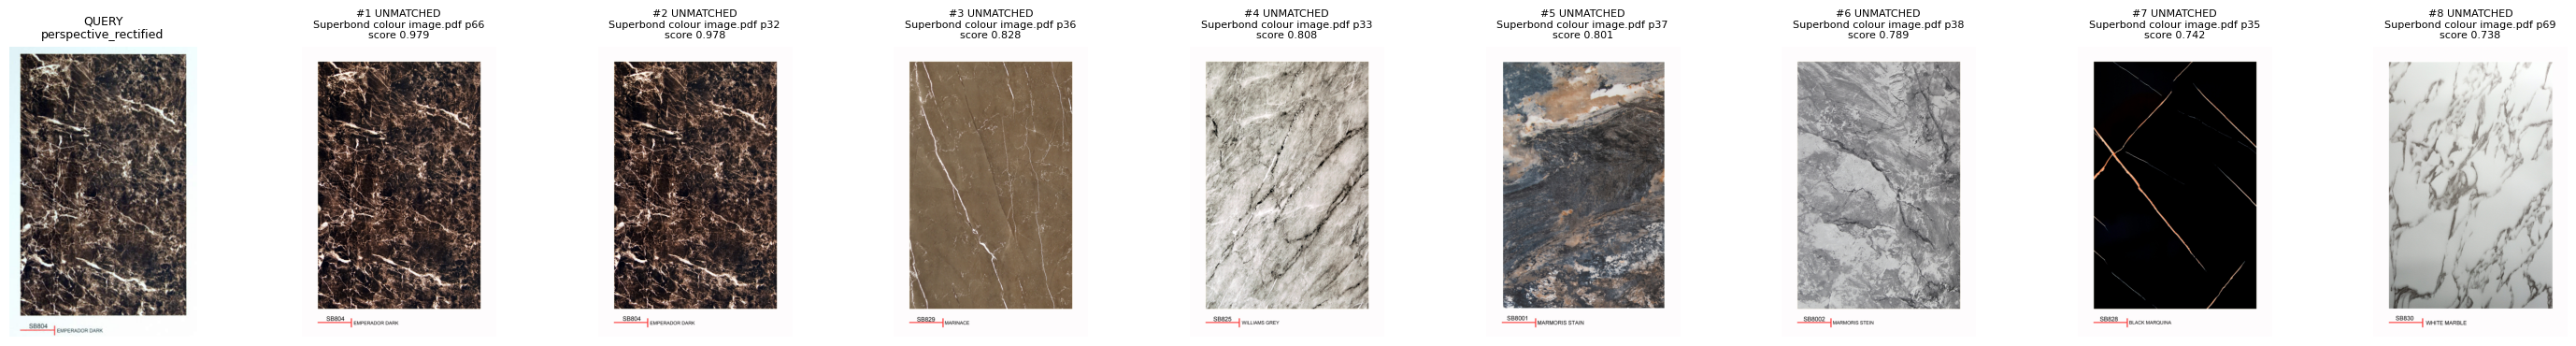

11:20:33 | INFO    | Lineage check for UNMATCHED: {'item_id': '2e10320006fe-p0066-i00', 'product_id': None, 'source_pdf': '/kaggle/input/datasets/mayankr293/terucon-catalogue-1/Superbond colour image.pdf', 'page_number': 66, 'stored_sha256': '4aa4c458f8403dd8c02cd4f5ea4f902fb46e8f68589ac7cd249cc18aa1733ebc', 'pdf_sha256_matches': True, 'crop_file_present': True, 'crop_file_sha256_matches': True, 'rerendered_sha256_matches': True}
11:20:33 | INFO    | Provenance overlay: /kaggle/working/backtrace/2e10320006fe-p0066-i00_provenance.png
11:20:33 | INFO    | Text query 'polished stone' via ['siglip_text', 'text_query', 'vertex_mm_text']


,rank,product_id,final_score,source_pdf,page_number,image_bbox,id_bbox,material_category,surface_finish,dominant_hex
0,1,UNMATCHED,0.97211,/kaggle/input/datasets/mayankr293/terucon-cata...,37,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#4C4C4E, #F2EFEF, #827872]"
1,2,UNMATCHED,0.86733,/kaggle/input/datasets/mayankr293/terucon-cata...,9,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#BA764C, #764D39, #FDFBFC]"
2,3,UNMATCHED,0.84326,/kaggle/input/datasets/mayankr293/terucon-cata...,32,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#271C1C, #F1ECEA, #624A41]"
3,4,UNMATCHED,0.82428,/kaggle/input/datasets/mayankr293/terucon-cata...,39,"[26.833, 15.0, 568.166, 827.0]",None,stone,matte,"[#4A4339, #544D42, #FDFBFC]"
4,5,UNMATCHED,0.81911,/kaggle/input/datasets/mayankr293/terucon-cata...,66,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#271C1C, #F1ECEA, #624A41]"


11:20:35 | INFO    | Hybrid photo+text query via ['dino_image', 'siglip_image', 'color_image', 'vertex_mm_image', 'siglip_text', 'text_query', 'vertex_mm_text']


,rank,product_id,final_score,source_pdf,page_number,image_bbox,id_bbox,material_category,surface_finish,dominant_hex
0,1,UNMATCHED,0.95280,/kaggle/input/datasets/mayankr293/terucon-cata...,66,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#271C1C, #F1ECEA, #624A41]"
1,2,UNMATCHED,0.93391,/kaggle/input/datasets/mayankr293/terucon-cata...,32,"[26.833, 15.0, 568.166, 827.0]",None,stone,polished,"[#271C1C, #F1ECEA, #624A41]"
2,3,UNMATCHED,0.76575,/kaggle/input/datasets/mayankr293/terucon-cata...,53,"[26.833, 15.0, 568.166, 827.0]",None,metal,textured,"[#393738, #FDFBFC, #4B4A4C]"
3,4,UNMATCHED,0.75150,/kaggle/input/datasets/mayankr293/terucon-cata...,39,"[26.833, 15.0, 568.166, 827.0]",None,stone,matte,"[#4A4339, #544D42, #FDFBFC]"
4,5,UNMATCHED,0.74848,/kaggle/input/datasets/mayankr293/terucon-cata...,62,"[26.833, 15.0, 568.166, 827.0]",None,laminate,satin,"[#6C442E, #4C2E1F, #FDFBFC]"


11:20:59 | INFO    | Self-retrieval under simulated phone capture:


,signal,recall@1,recall@5,mrr,queries
0,siglip_image,0.925,1.000,0.962500,40
1,FUSED,0.925,1.000,0.962500,40
2,dino_image,0.800,0.975,0.876250,40
3,color_image,0.475,0.775,0.608988,40


11:21:24 | INFO    | Resolved 'render' model -> gemini-nano-banana-2.1
11:21:24 | INFO    | Rendered 2e10320006fe-p0066-i00 with gemini-nano-banana-2.1 -> /kaggle/working/renders/20261025T112124_2e10320006fe-p0066-i00.png


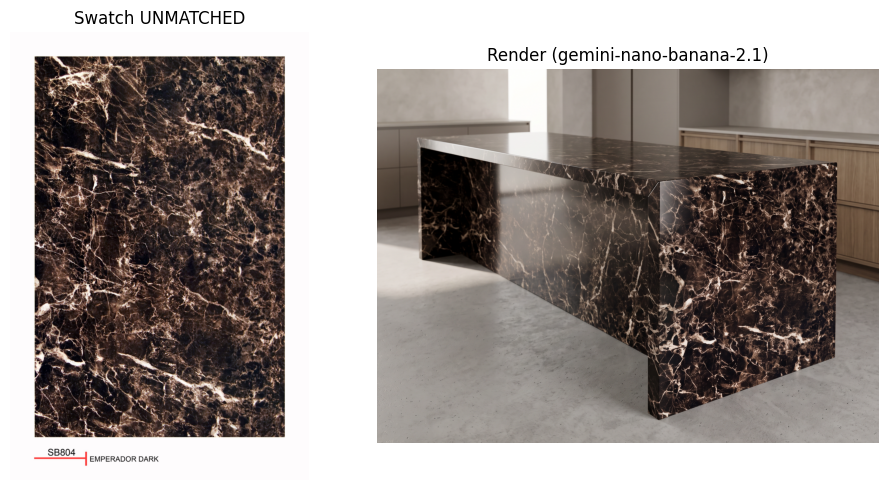

In [7]:
# =============================================================================
# CELL 7 — Nano Banana texture renderer, orchestration, end-to-end demo
# =============================================================================
SUPPORTED_ASPECT_RATIOS = ("1:1", "2:3", "3:2", "3:4", "4:3", "4:5", "5:4", "9:16", "16:9", "21:9")
DEFAULT_RENDER_OBJECTS = {
    "textile_fabric": "a modern lounge armchair with tight upholstery and a loose seat cushion",
    "leather": "a mid-century lounge chair upholstered in this leather",
    "carpet_rug": "a large rectangular area rug in a bright living room",
    "wood_veneer": "a run of flat-panel kitchen cabinet doors",
    "solid_wood": "a dining table top with a softly eased edge",
    "laminate": "a run of flat-panel kitchen cabinet doors",
    "stone": "a kitchen island with a waterfall countertop",
    "ceramic_tile": "a bathroom feature wall laid with these tiles",
    "metal": "a wall-mounted range hood and a cabinet pull",
    "glass": "a glass shower partition",
    "wallcovering_paper": "a living-room feature wall",
}
DEFAULT_SCENE_TARGET = ("the most prominent large surface that would plausibly be made of this material "
                        "(for example upholstery, cabinet fronts, a countertop, a wall or the floor)")


def nearest_aspect_ratio(width, height):
    target = math.log(max(width, 1) / max(height, 1))
    best = "1:1"
    best_distance = float("inf")
    for ratio in SUPPORTED_ASPECT_RATIOS:
        numerator, denominator = ratio.split(":")
        distance = abs(math.log(float(numerator) / float(denominator)) - target)
        if distance < best_distance:
            best = ratio
            best_distance = distance
    return best


def model_supports_image_size(model_name):
    return "2.5-flash-image" not in model_name


def extract_generated_image(response):
    image_bytes = None
    mime_type = None
    texts = []
    for candidate in (response.candidates or []):
        content = getattr(candidate, "content", None)
        if content is None or not content.parts:
            continue
        for part in content.parts:
            if getattr(part, "thought", False):
                continue  # interim "thinking" images from Pro-tier models
            inline = getattr(part, "inline_data", None)
            if inline is not None and inline.data:
                image_bytes = inline.data
                mime_type = inline.mime_type or "image/png"
            elif getattr(part, "text", None):
                texts.append(part.text)
    if image_bytes is None:
        raise EmptyModelResponse(
            f"No image returned (finish_reason={describe_finish_reason(response)}); text={' '.join(texts)[:300]}",
            retryable=False)
    return image_bytes, mime_type, "\n".join(texts)


@dataclass
class RenderResult:
    render_id: str
    output_path: Path
    metadata_path: Path
    model: str
    item_id: str
    product_id: Optional[str]
    model_text: str


class NanoBananaRenderer:
    def __init__(self, cfg, store, manager, runner):
        self.cfg = cfg
        self.store = store
        self.manager = manager
        self.runner = runner

    def _catalog_row(self, item_id):
        row = self.store.get_item(item_id)
        if row is None:
            raise KeyError(item_id)
        caption = self.store.query("SELECT profile_json FROM captions WHERE item_id = ? AND status = 'ok'", (item_id,))
        row["profile"] = json.loads(caption[0]["profile_json"]) if caption else {}
        color = self.store.query("SELECT extra_json FROM embeddings WHERE item_id = ? AND pillar = 'color'", (item_id,))
        row["color_meta"] = json.loads(color[0]["extra_json"]) if color and color[0]["extra_json"] else {}
        return row

    def build_instruction(self, row, has_scene, target_description, extra_instructions):
        profile = row["profile"]
        product_label = row["product_id"] or row["item_id"]
        hex_text = ", ".join(row["color_meta"].get("dominant_hex", [])) or "as seen in the swatch"
        material_prompt = profile.get("nano_banana_render_prompt") or (
            "Reproduce the swatch's exact weave/grain geometry, relief, roughness and colour variation.")
        scale_text = profile.get("pattern_scale") or "true real-world scale"
        finish_text = profile.get("surface_finish") or "as seen in the swatch"
        specular_text = profile.get("specular_behavior") or "as seen in the swatch"
        if has_scene:
            target = target_description or DEFAULT_SCENE_TARGET
            task = (f"IMAGE 1 is the reference material swatch (catalogue product {product_label}). "
                    f"IMAGE 2 is the target scene photo. Re-surface {target} in IMAGE 2 with the exact material "
                    f"from IMAGE 1, and keep everything else in IMAGE 2 unchanged (geometry, camera, background, "
                    f"other objects, framing).")
            lighting = ("Re-light the material physically under IMAGE 2's existing light: same light direction, "
                        "colour temperature, shadow softness and ambient occlusion.")
        else:
            category = profile.get("material_category") or ""
            target = target_description or DEFAULT_RENDER_OBJECTS.get(category, "a minimalist product surface")
            task = (f"IMAGE 1 is the reference material swatch (catalogue product {product_label}). Create a "
                    f"photorealistic product visualisation of {target}, finished in the exact material from IMAGE 1, "
                    f"in a neutral studio with a soft key light from the upper left and gentle fill.")
            lighting = "Use physically based shading; show the material's specular response at a grazing angle."
        lines = [
            "You are a photorealistic material-transfer renderer.",
            task,
            "Hard constraints:",
            "1. Preserve the swatch's micro-texture exactly: weave/grain geometry and direction, pore or yarn detail, "
            "relief depth. Do not simplify, smooth or invent pattern elements.",
            f"2. Preserve colour tone exactly; match {hex_text}. No stylisation, saturation boost or recolouring.",
            f"3. {lighting} Finish: {finish_text}. Specular behaviour: {specular_text}.",
            f"4. Map the material along the surface's perspective, curvature, folds and seams at physical scale "
            f"({scale_text}); no stretching, mirroring or visible tiling seams.",
            "5. No text, logos, labels or watermarks in the output.",
            f"Material description: {material_prompt}",
        ]
        if extra_instructions:
            lines.append(f"Additional direction: {extra_instructions}")
        lines.append("Return one photorealistic image.")
        return "\n".join(lines)

    def render(self, item, scene=None, target_description=None, extra_instructions="", aspect_ratio=None):
        if isinstance(item, str):
            item_id = item                 # an item_id
        else:
            item_id = str(item["item_id"])  # a search-result row (pandas Series) or dict
        row = self._catalog_row(item_id)
        swatch_rgb = resize_max_side(load_rgb(row["crop_filepath"]), self.cfg.render_swatch_max_side_px)
        swatch_bytes = encode_rgb(swatch_rgb, "png")
        scene_bytes = None
        scene_label = None
        if scene is not None:
            scene_rgb = resize_max_side(load_rgb(scene), self.cfg.render_scene_max_side_px)
            scene_bytes = encode_rgb(scene_rgb, "jpeg", 93)
            scene_label = str(scene) if isinstance(scene, (str, Path)) else "<in-memory scene>"
            if aspect_ratio is None:
                aspect_ratio = nearest_aspect_ratio(scene_rgb.shape[1], scene_rgb.shape[0])
        if aspect_ratio is None:
            aspect_ratio = "4:3"
        instruction = self.build_instruction(row, scene_bytes is not None, target_description, extra_instructions)
        contents = [instruction, "IMAGE 1 - reference material swatch:",
                    genai_types.Part.from_bytes(data=swatch_bytes, mime_type="image/png")]
        if scene_bytes is not None:
            contents.append("IMAGE 2 - target scene:")
            contents.append(genai_types.Part.from_bytes(data=scene_bytes, mime_type="image/jpeg"))

        def render_config(model_name):
            if model_supports_image_size(model_name):
                image_config = genai_types.ImageConfig(aspect_ratio=aspect_ratio, image_size=self.cfg.render_image_size)
            else:
                image_config = genai_types.ImageConfig(aspect_ratio=aspect_ratio)
            return genai_types.GenerateContentConfig(response_modalities=["TEXT", "IMAGE"], image_config=image_config)

        model_name, response = self.runner.run(self.manager.generate_content_with_fallback(
            "render", self.cfg.image_model_candidates, contents, render_config))
        image_bytes, mime_type, model_text = extract_generated_image(response)

        render_id = f"{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')}_{item_id}"
        extension = ".jpg" if "jpeg" in (mime_type or "") else ".png"
        output_path = self.cfg.renders_dir / f"{render_id}{extension}"
        metadata_path = self.cfg.renders_dir / f"{render_id}.json"
        atomic_write_bytes(output_path, image_bytes)
        metadata = {
            "render_id": render_id, "created_at": utc_now_iso(), "model": model_name, "item_id": item_id,
            "product_id": row["product_id"], "source_pdf": row["source_pdf"], "page_number": row["page_number"],
            "image_bbox": json.loads(row["image_bbox"]), "crop_filepath": row["crop_filepath"],
            "crop_sha256": row["sha256_hash"], "scene": scene_label, "aspect_ratio": aspect_ratio,
            "image_size": self.cfg.render_image_size if model_supports_image_size(model_name) else None,
            "prompt": instruction, "model_text": model_text,
        }
        atomic_write_bytes(metadata_path, json.dumps(metadata, indent=2).encode("utf-8"))
        self.store.record_render({"render_id": render_id, "item_id": item_id, "product_id": row["product_id"],
                                  "model": model_name, "scene_path": scene_label, "output_path": str(output_path),
                                  "metadata_path": str(metadata_path), "prompt": instruction})
        LOGGER.info("Rendered %s with %s -> %s", row["product_id"] or item_id, model_name, output_path)
        return RenderResult(render_id, output_path, metadata_path, model_name, item_id, row["product_id"], model_text)


@dataclass
class PipelineComponents:
    cfg: PipelineConfig
    hardware: HardwareProfile
    store: StateStore
    extractor: CatalogueExtractor
    lineage: LineageTracer
    encoders: DualGPUEncoderBank
    manager: Optional[VertexGenAIManager]
    runner: AsyncRunner
    synthesizer: Optional[GeminiMaterialSynthesizer]
    index: MultiVectorIndex
    retriever: HybridRetriever
    renderer: Optional[NanoBananaRenderer]
    feature_versions: Dict[str, str]


def run_pipeline(cfg, hardware, encoders=None, manager=None, use_vertex=True):
    cfg.ensure_dirs()
    store = StateStore(cfg.state_db_path)
    feature_versions = compute_feature_versions(cfg)

    def export_manifest():
        store.export_manifest(cfg.manifest_path, cfg.page_audit_path, feature_versions)

    runner = get_async_runner()
    if manager is None and use_vertex:
        try:
            manager = VertexGenAIManager(cfg)
        except (SecretUnavailableError, FileNotFoundError, ValueError, KeyError) as exc:
            LOGGER.warning("Vertex AI disabled (%s). Pillar 3 captions, Vertex embeddings and rendering are skipped.", exc)

    LOGGER.info("== Stage 1/5: PDF extraction ==")
    extractor = CatalogueExtractor(cfg, store, on_pdf_complete=export_manifest)
    extractor.run()
    export_manifest()

    LOGGER.info("== Stage 2/5: DINOv2 + SigLIP + CIELAB on %d GPU(s) ==", hardware.gpu_count)
    if encoders is None:
        encoders = DualGPUEncoderBank(cfg, hardware)
    LocalFeatureExtractor(cfg, store, encoders).run()
    export_manifest()

    synthesizer = None
    if manager is not None:
        LOGGER.info("== Stage 3/5: Vertex multimodal image embeddings ==")
        VertexMultimodalImageEmbedder(cfg, store, manager, runner).run()
        LOGGER.info("== Stage 4/5: Gemini structured material synthesis + description vectors ==")
        synthesizer = GeminiMaterialSynthesizer(cfg, store, manager, runner, on_checkpoint=export_manifest)
        synthesizer.run()
        DescriptionEmbeddingIndexer(cfg, store, manager, runner).run()
        export_manifest()

    LOGGER.info("== Stage 5/5: FAISS multi-vector index ==")
    index = MultiVectorIndex(cfg, store).build_or_load(feature_versions)
    retriever = HybridRetriever(cfg, index, QueryEncoder(cfg, encoders, manager, runner, synthesizer))
    renderer = NanoBananaRenderer(cfg, store, manager, runner) if manager is not None else None
    lineage = LineageTracer(cfg, store, extractor)
    LOGGER.info("State summary: %s", store.summary())
    return PipelineComponents(cfg, hardware, store, extractor, lineage, encoders, manager, runner, synthesizer,
                              index, retriever, renderer, feature_versions)


def _display(value):
    try:
        from IPython.display import display
        display(value)
    except Exception:
        print(value)


def pick_query_photo(cfg, catalog, seed=7):
    photos = list_images(cfg.query_photo_dir)
    if photos:
        return photos[0], None, f"user photo {photos[0].name}"
    truth_item = str(np.random.default_rng(seed).choice(catalog["item_id"].values))
    simulated = SyntheticPhoneCapture(seed)(load_rgb(catalog.loc[truth_item, "crop_filepath"]))
    return simulated, truth_item, f"synthetic phone capture of {catalog.loc[truth_item, 'product_id']}"


def run_demo(components, run_evaluation=True, run_render=True):
    cfg = components.cfg
    retriever = components.retriever
    catalog = components.index.catalog
    if catalog.empty:
        LOGGER.warning("Catalogue is empty: check the PDF at %s and re-run.", cfg.pdf_path)
        return None
    display_columns = ["rank", "product_id", "final_score", "source_pdf", "page_number", "image_bbox", "id_bbox",
                       "material_category", "surface_finish", "dominant_hex"]

    # 1) Photo query --------------------------------------------------------------
    query_source, truth_item, query_label = pick_query_photo(cfg, catalog)
    LOGGER.info("Photo query: %s", query_label)
    photo_result = retriever.search(photo=query_source)
    _display(photo_result.results[[column for column in display_columns if column in photo_result.results]])
    LOGGER.info("Signals: %s", photo_result.signal_weights)
    if truth_item is not None:
        LOGGER.info("Ground truth item %s ranked #%s", truth_item,
                    int(np.where(photo_result.fused_order == photo_result.pool_item_ids.index(truth_item))[0][0]) + 1)
    show_search_results(photo_result, photo_result.query_info.get("rectified_rgb"),
                        save_path=cfg.work_dir / "demo_photo_query.png")
    top_match = photo_result.results.iloc[0]

    # 2) Backtracking proof -------------------------------------------------------
    verification = components.lineage.verify(top_match["item_id"])
    LOGGER.info("Lineage check for %s: %s", top_match["product_id"], verification)
    provenance_path = components.lineage.draw_provenance(top_match["item_id"])
    LOGGER.info("Provenance overlay: %s", provenance_path)

    # 3) Text query and hybrid query ---------------------------------------------
    text_result = None
    hybrid_result = None
    text_query = None
    if isinstance(top_match.get("surface_finish"), str) and isinstance(top_match.get("material_category"), str):
        text_query = f"{top_match['surface_finish'].replace('_', ' ')} {top_match['material_category'].replace('_', ' ')}"
    else:
        text_query = "matte woven textured fabric"
    text_result = retriever.search(text=text_query, top_k=5)
    LOGGER.info("Text query '%s' via %s", text_query, text_result.signal_names)
    _display(text_result.results[[column for column in display_columns if column in text_result.results]])
    hybrid_result = retriever.search(photo=query_source, text="same texture in a darker tone", top_k=5,
                                     describe_photo=False)
    LOGGER.info("Hybrid photo+text query via %s", hybrid_result.signal_names)
    _display(hybrid_result.results[[column for column in display_columns if column in hybrid_result.results]])

    # 4) Self-retrieval benchmark under simulated phone capture -------------------
    evaluation = None
    if run_evaluation:
        evaluation = evaluate_self_retrieval(retriever, sample_size=min(40, len(catalog)))
        LOGGER.info("Self-retrieval under simulated phone capture:")
        _display(evaluation)

    # 5) Nano Banana render -------------------------------------------------------
    render_result = None
    if run_render and components.renderer is not None:
        scenes = list_images(cfg.scene_dir)
        scene = scenes[0] if scenes else None
        try:
            render_result = components.renderer.render(top_match, scene=scene)
            import matplotlib.pyplot as plt
            panels = [load_rgb(top_match["crop_filepath"])]
            titles = [f"Swatch {top_match['product_id']}"]
            if scene is not None:
                panels.append(load_rgb(scene))
                titles.append("Target scene")
            panels.append(load_rgb(render_result.output_path))
            titles.append(f"Render ({render_result.model})")
            figure, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 5))
            for axis, panel, title in zip(np.atleast_1d(axes), panels, titles):
                axis.imshow(panel)
                axis.set_title(title)
                axis.axis("off")
            plt.tight_layout()
            plt.show()
        except Exception as exc:
            LOGGER.error("Rendering failed: %s", exc)
    return {"photo": photo_result, "text": text_result, "hybrid": hybrid_result, "evaluation": evaluation,
            "verification": verification, "provenance": provenance_path, "render": render_result}


if __name__ == "__main__" and os.environ.get("CATALOG_AUTORUN", "1") == "1":
    COMPONENTS = run_pipeline(CFG, HARDWARE)
    DEMO = run_demo(COMPONENTS)

### Using the engine after the run
```python
R = COMPONENTS.retriever
hits = R.search(photo="/kaggle/input/query-photos/sofa_fabric.jpg", top_k=10)          # photo
hits = R.search(text="brushed brass with fine linear grain", top_k=10)                 # text
hits = R.search(photo=my_photo, text="but warmer", weights={"dino": .4, "color": .2, "mm": .2, "text": .2})
hits = R.search(photo=my_photo, filters={"material_category": ["textile_fabric"]})    # metadata filter
COMPONENTS.lineage.verify(hits.results.iloc[0]["item_id"])                            # backtracking proof
COMPONENTS.renderer.render(hits.results.iloc[0], scene="/kaggle/input/target-scenes/room.jpg",
                           target_description="the three-seat sofa")
```